In [1]:

from __future__ import print_function, division
from collections import defaultdict, OrderedDict
import gzip
import pickle
import json
import os
import uproot
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
from coffea import hist, processor 
from coffea.hist import plot
from coffea.util import load, save

In [2]:
!pwd

/cms/scratch/runiyal/new_coffea/decaf/analysis/Rishabh_NB/new_coffea_nbs/Plotting


In [29]:
hists

{'bkg': {'template': <Hist (process,region,systematic,mT) instance at 0x7fe3dba92710>,
  'ele_phi': <Hist (process,region,ele_phi) instance at 0x7fe3de6688d0>,
  'sumw': <Hist (process,sumw) instance at 0x7fe3de634a90>,
  'j1pt': <Hist (process,region,j1pt) instance at 0x7fe3de64d240>,
  'eT_miss_corrected_phi': <Hist (process,region,eT_miss_corrected_phi) instance at 0x7fe3de5c8c88>,
  'metphi': <Hist (process,region,metphi) instance at 0x7fe3de51fb00>,
  'ndflvM': <Hist (process,region,ndflvM) instance at 0x7fe3de4b57b8>,
  'dr_mu_lj': <Hist (process,region,dr_mu_lj) instance at 0x7fe3de4399b0>,
  'ele_pT': <Hist (process,region,ele_pT) instance at 0x7fe3de3f8b00>,
  'mu_eta': <Hist (process,region,mu_eta) instance at 0x7fe3de5ca588>,
  'j1phi': <Hist (process,region,j1phi) instance at 0x7fe3dd5a63c8>,
  'leading_mu_pT': <Hist (process,region,leading_mu_pT) instance at 0x7fe3de672e48>,
  'cutflow': <Hist (process,region,cut) instance at 0x7fe3de686f98>,
  'ndflvL': <Hist (process,reg

In [64]:
red = "/cms/scratch/runiyal/new_coffea/decaf/analysis/hists/UL_lep_monotop_v1_test_2017.merged"

In [65]:
hists = load(red)


In [68]:
hists['template']

<Hist (dataset,region,systematic,mT) instance at 0x7fc02fddd438>

In [69]:
hists['template'].identifiers('dataset')

[<StringBin (HF--WJetsToLNu_Pt-400To600_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8) instance at 0x7fc02ff4e470>,
 <StringBin (LF--WJetsToLNu_Pt-400To600_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8) instance at 0x7fc02ff66e80>,
 <StringBin (WZ_TuneCP5_13TeV-pythia8) instance at 0x7fc02ff66f98>,
 <StringBin (QCD_Pt_800to1000_TuneCP5_13TeV_pythia8) instance at 0x7fc02fec1e48>,
 <StringBin (SingleElectron) instance at 0x7fc02fec11d0>,
 <StringBin (QCD_Pt_470to600_TuneCP5_13TeV_pythia8) instance at 0x7fc02feb0c50>,
 <StringBin (SingleMuon) instance at 0x7fc02feb0a58>,
 <StringBin (HF--WJetsToLNu_Pt-250To400_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8) instance at 0x7fc02feb0f98>,
 <StringBin (LF--WJetsToLNu_Pt-250To400_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8) instance at 0x7fc02feb0f60>,
 <StringBin (QCD_Pt_1000to1400_TuneCP5_13TeV_pythia8) instance at 0x7fc02feb0e10>,
 <StringBin (TTToSemiLeptonic_TuneCP5_13TeV-powheg-pythia8) instance at 0x7fc02feb0dd8>,
 <StringBin (

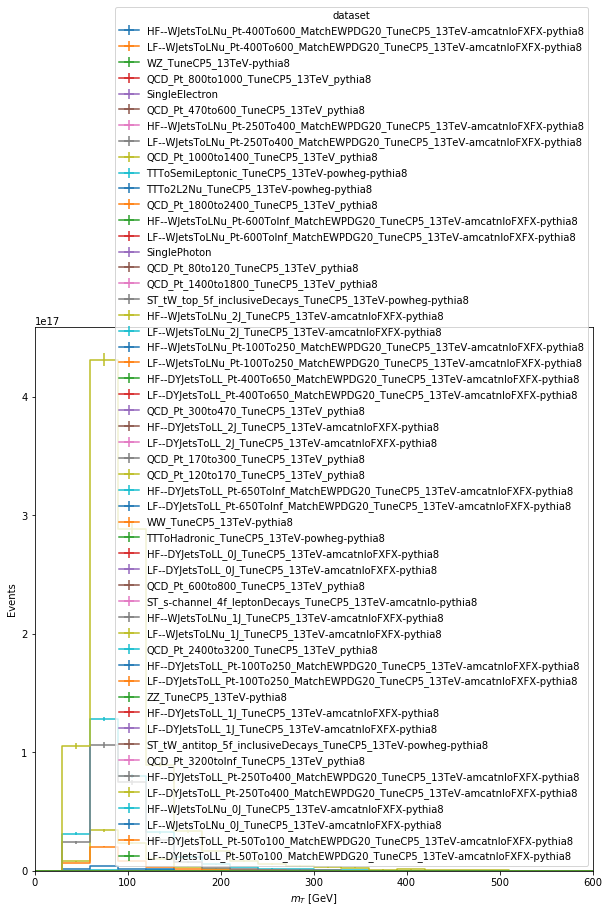

In [72]:

from coffea.hist import plot
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,1, figsize=(10,10))



plot.plot1d(hists['template'].integrate('region', 'wjete').integrate('systematic','nominal'),
            overlay='dataset', ax=ax)

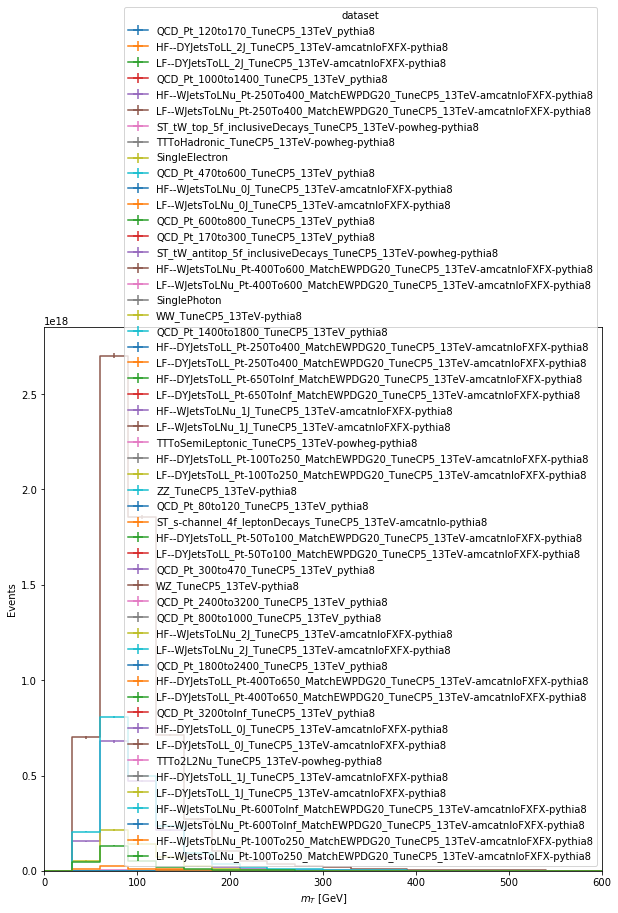

In [74]:
from coffea.hist import plot
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,1, figsize=(10,10))



plot.plot1d(hists['mT'].integrate('region', 'wjete'),
            overlay='dataset', ax=ax)



In [59]:
hists['bkg']['mT'].integrate('region', 'wjete').integrate('process').values()

{(): array([0.00000000e+00, 5.78266543e+04, 1.97849004e+05, 1.07874601e+05,
        4.91286588e+04, 2.19579292e+04, 8.73571442e+03, 4.93520199e+03,
        3.03304131e+03, 2.11206116e+03, 1.37798983e+03, 8.14911703e+02,
        6.51094802e+02, 4.72235889e+02, 2.98432149e+02, 2.53542510e+02,
        2.11834698e+02, 1.90768796e+02, 7.67052815e+01, 8.62697867e+01])}

In [54]:
hists['bkg']['template'].integrate('region', 'wjete').integrate('process').values()


{('nominal',): array([0.00000000e+00, 8.47387633e+03, 3.04838880e+04, 1.70505150e+04,
        6.21114622e+03, 2.95584539e+03, 1.26663284e+03, 7.33508770e+02,
        4.82413177e+02, 3.07935827e+02, 2.25276337e+02, 1.45462278e+02,
        9.58022026e+01, 7.93519734e+01, 4.46573935e+01, 4.44955122e+01,
        3.40154138e+01, 2.63939545e+01, 2.28017331e+01, 4.54419370e+00]),
 ('btagUp',): array([0.00000000e+00, 8.47387633e+03, 3.04838880e+04, 1.70505150e+04,
        6.21114622e+03, 2.95584539e+03, 1.26663284e+03, 7.33508770e+02,
        4.82413177e+02, 3.07935827e+02, 2.25276337e+02, 1.45462278e+02,
        9.58022026e+01, 7.93519734e+01, 4.46573935e+01, 4.44955122e+01,
        3.40154138e+01, 2.63939545e+01, 2.28017331e+01, 4.54419370e+00]),
 ('btagDown',): array([0.00000000e+00, 8.47387633e+03, 3.04838880e+04, 1.70505150e+04,
        6.21114622e+03, 2.95584539e+03, 1.26663284e+03, 7.33508770e+02,
        4.82413177e+02, 3.07935827e+02, 2.25276337e+02, 1.45462278e+02,
        9.58022026

In [34]:
hists = load("../../../Rishabh_NB/study_scaled_files/no_dphi_sel_lep_monotop_v1_2017.scaled")
data={
    '2017':{
        'sre': 'SingleElectron',
        'srm': 'SingleMuon',
        'wjetm': 'SingleMuon',
        'ttbarm': 'SingleMuon',
        'wjete': 'SingleElectron',
        'ttbare': 'SingleElectron',
#         'zmcr': 'MET',
#         'zecr': 'EGamma',
#         'gcr': 'EGamma'
    }
}

data_hists   = hists['data']
bkg_hists    = hists['bkg']
signal_hists = hists['sig']

In [35]:
bkg_hists['template'].identifiers('systematic')

[<StringBin (btagDown) instance at 0x7fe3dd635ac8>,
 <StringBin (btagUp) instance at 0x7fe3dd635be0>,
 <StringBin (ew1Down) instance at 0x7fe3de2d9c50>,
 <StringBin (ew1Up) instance at 0x7fe3dd541c18>,
 <StringBin (ew2GDown) instance at 0x7fe3de2d91d0>,
 <StringBin (ew2GUp) instance at 0x7fe3de2d92b0>,
 <StringBin (ew2WDown) instance at 0x7fe3de2d94a8>,
 <StringBin (ew2WUp) instance at 0x7fe3de2d9358>,
 <StringBin (ew2ZDown) instance at 0x7fe3de2d9630>,
 <StringBin (ew2ZUp) instance at 0x7fe3de2d95f8>,
 <StringBin (ew3GDown) instance at 0x7fe3de2d97b8>,
 <StringBin (ew3GUp) instance at 0x7fe3de2d92e8>,
 <StringBin (ew3WDown) instance at 0x7fe3de2d97f0>,
 <StringBin (ew3WUp) instance at 0x7fe3de2d9908>,
 <StringBin (ew3ZDown) instance at 0x7fe3de2d9d68>,
 <StringBin (ew3ZUp) instance at 0x7fe3de2d9a58>,
 <StringBin (mixDown) instance at 0x7fe3de2d9ba8>,
 <StringBin (mixUp) instance at 0x7fe3de2d9c18>,
 <StringBin (muFDown) instance at 0x7fe3de322be0>,
 <StringBin (muFUp) instance at 0x7

In [40]:
bkg_hists['template'].integrate('region','wjetm').integrate('process')

<Hist (systematic) instance at 0x7fe3de392a20>

In [43]:
bkg_hists['template'].integrate('region').integrate('process').integrate('systematic', 'qcd3Up').values()

{(): array(85238.835514)}

In [23]:
import numpy as np

In [29]:
1/np.nan

nan

In [43]:
for i in hists.keys():
    if "template" in i or "sumw" in i or "EventCount" in i: continue
    print(i,"+=>", hists[i].integrate("region", "wjetm").integrate("dataset").values())

AttributeError: 'dict' object has no attribute 'integrate'

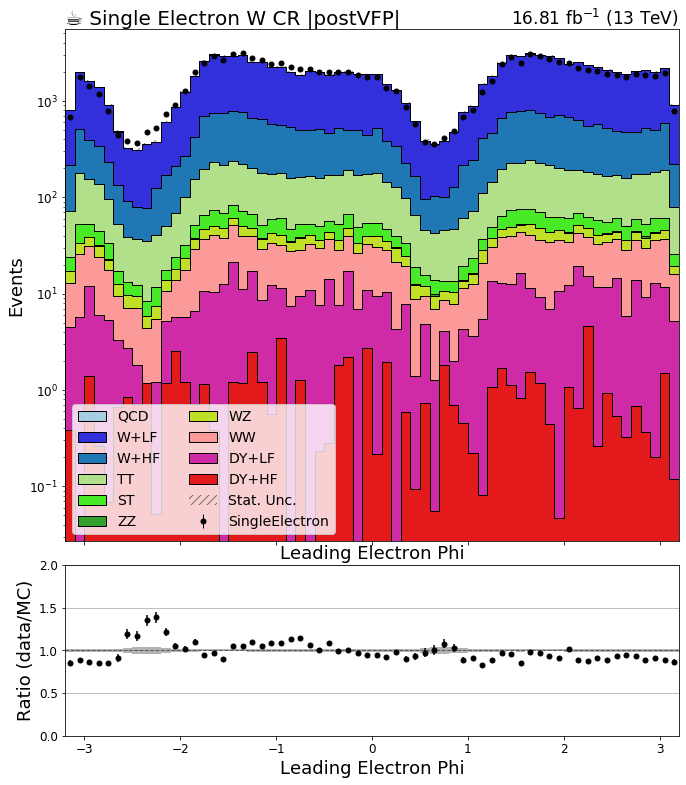

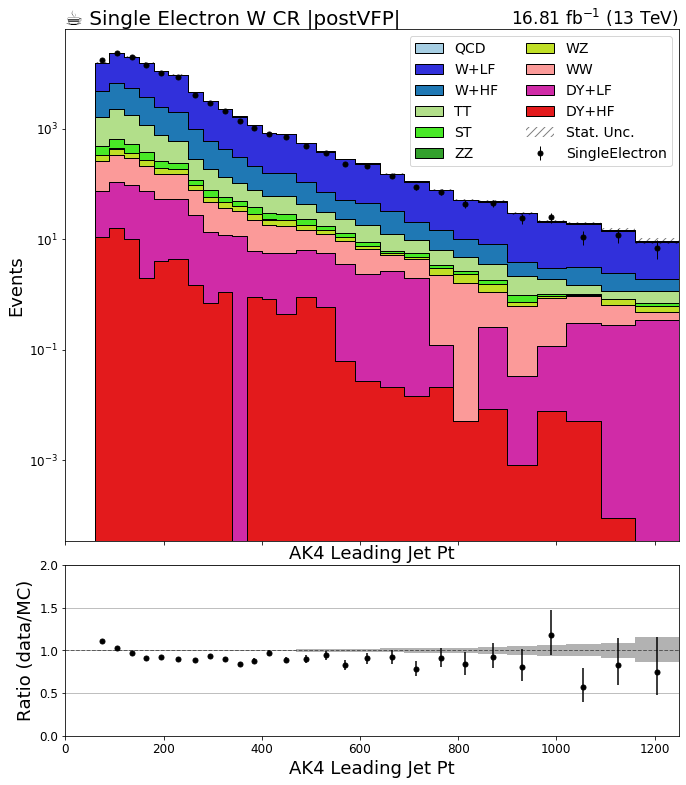

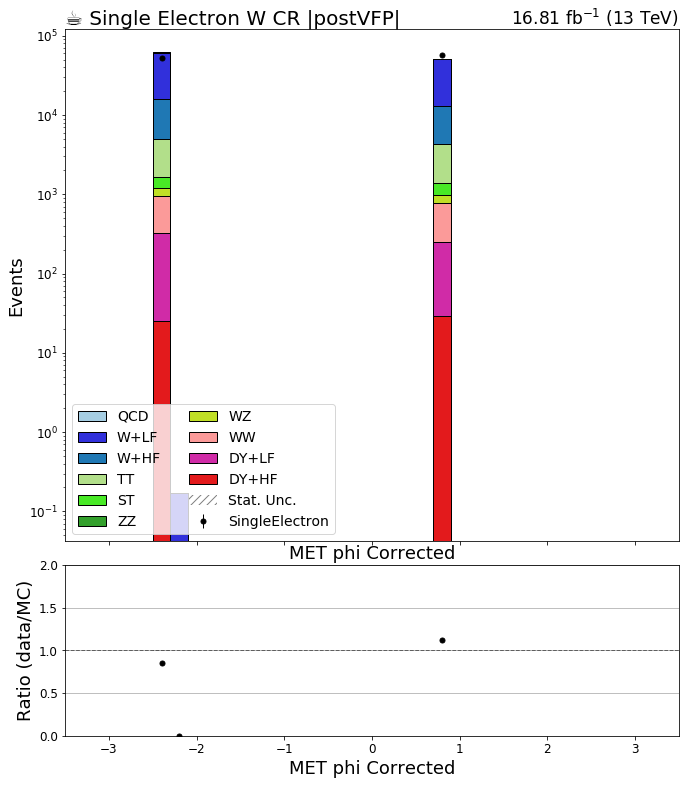

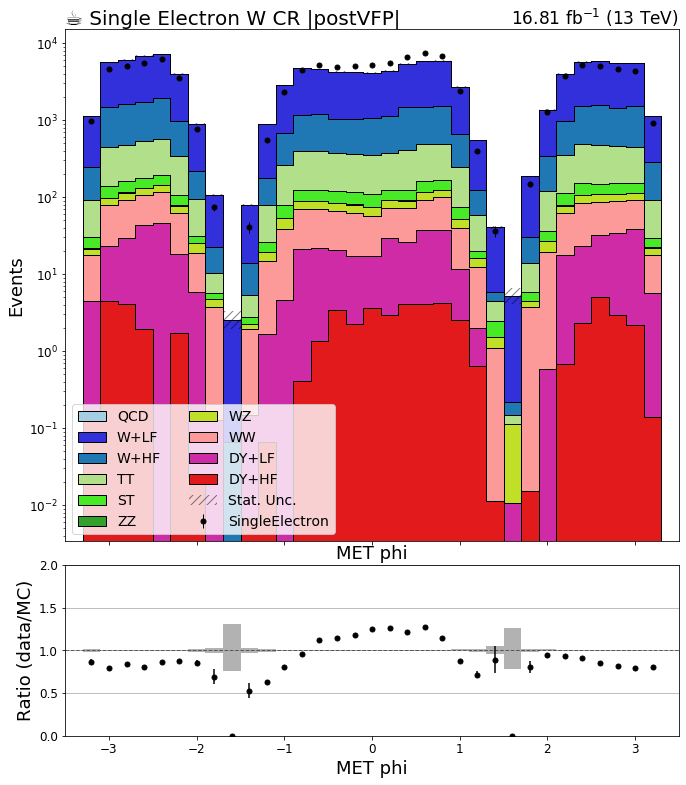

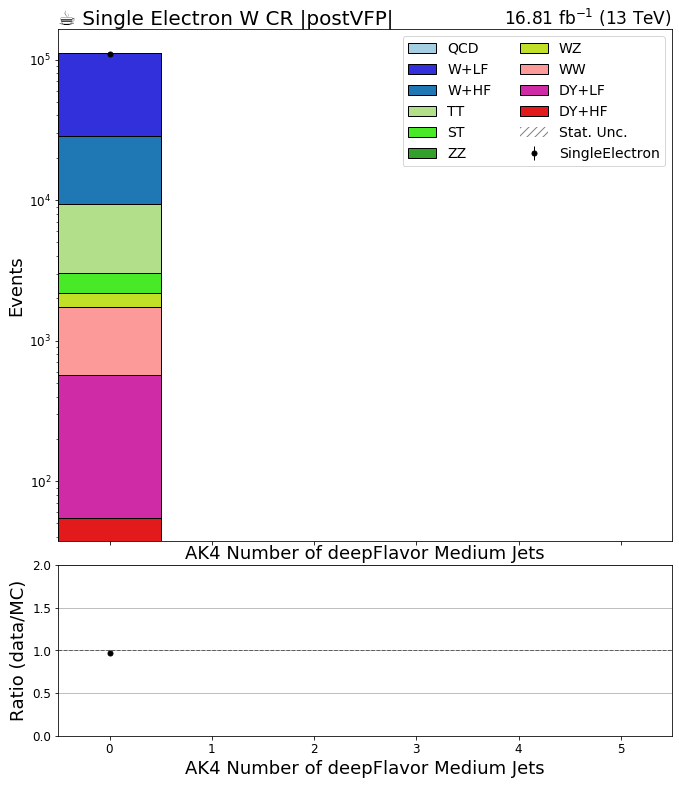

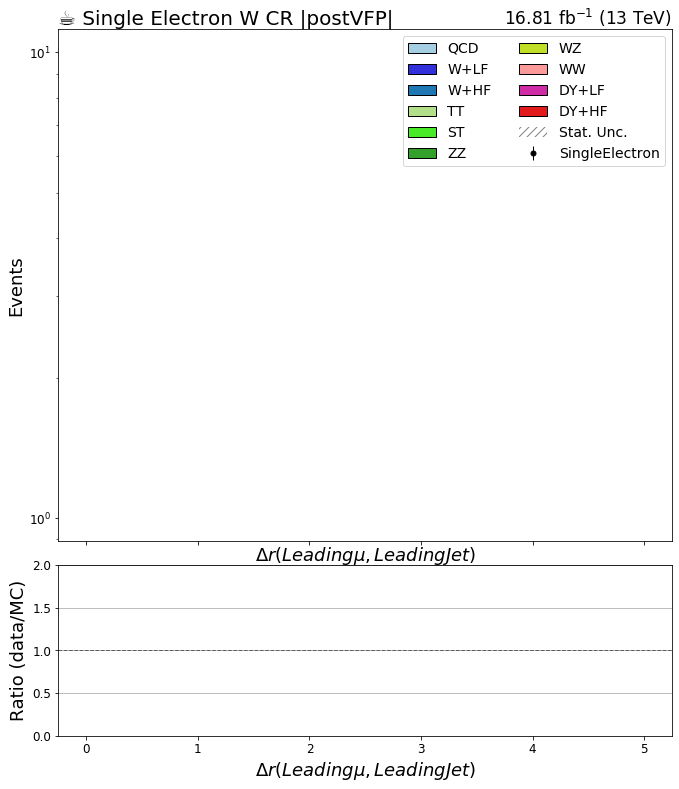

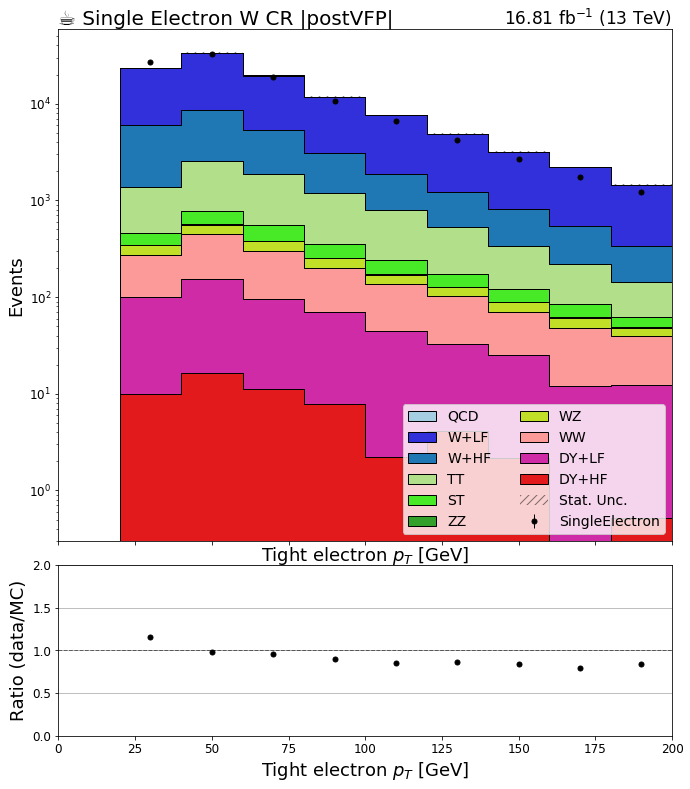

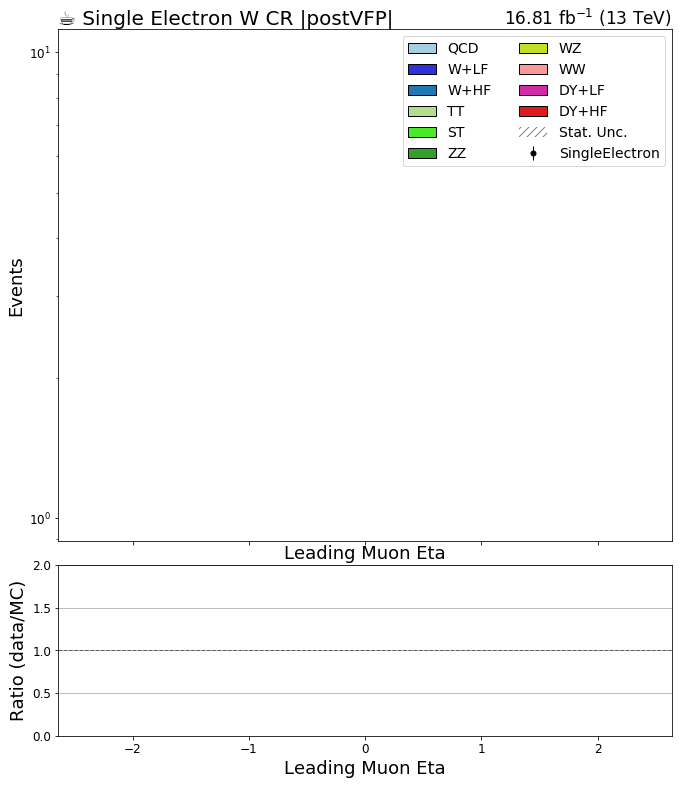

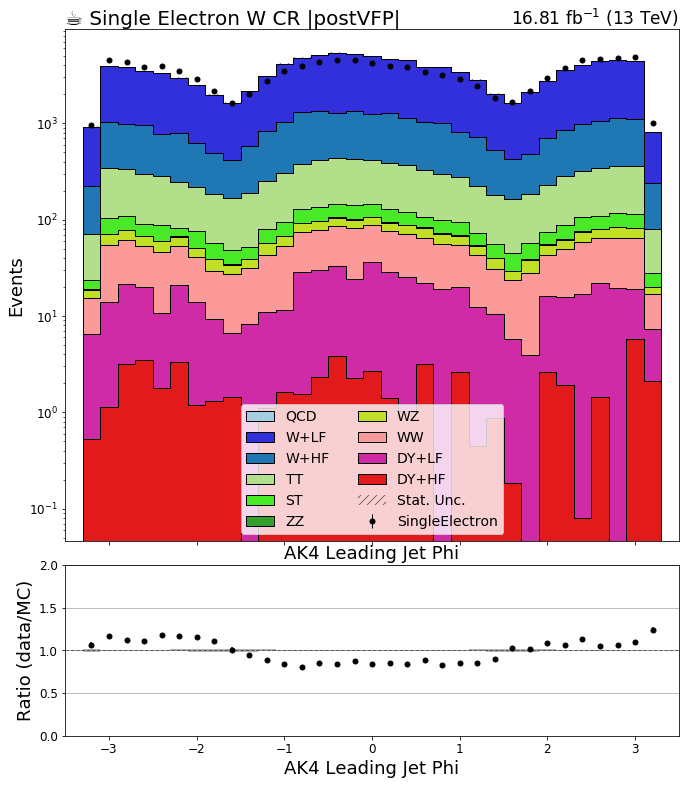

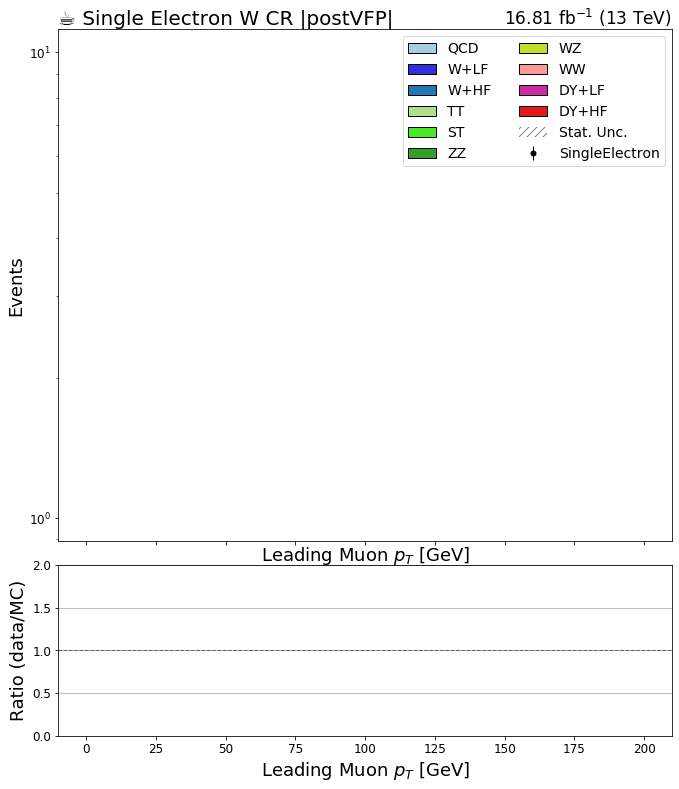

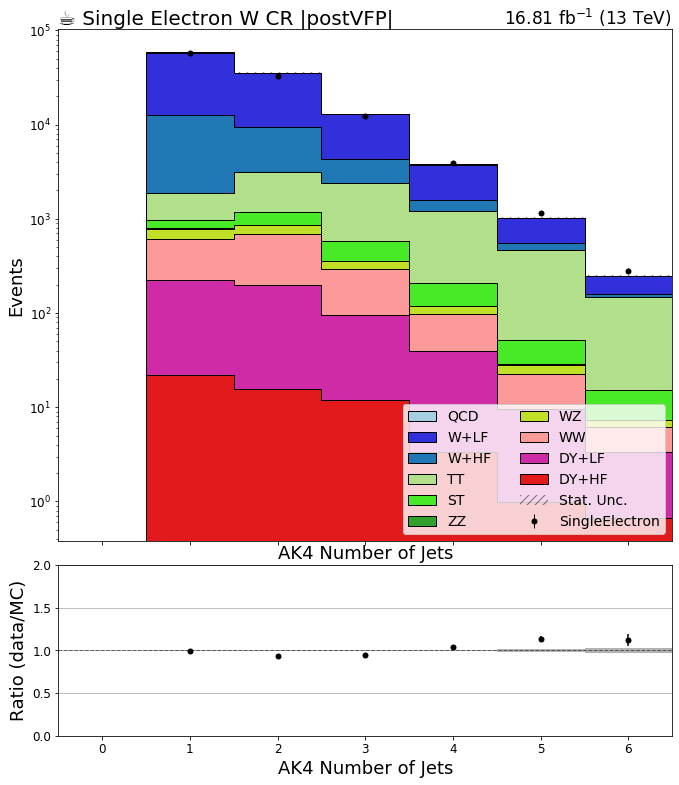

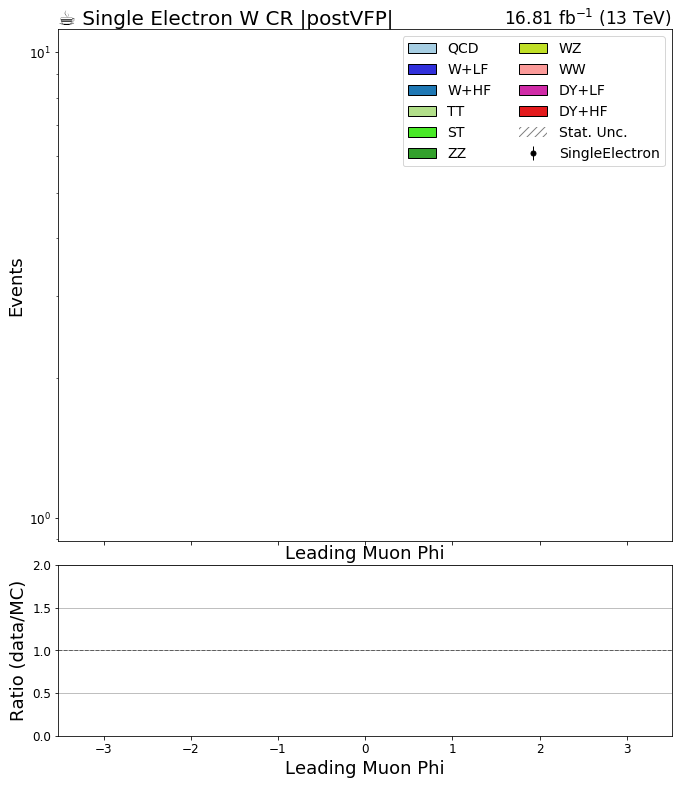

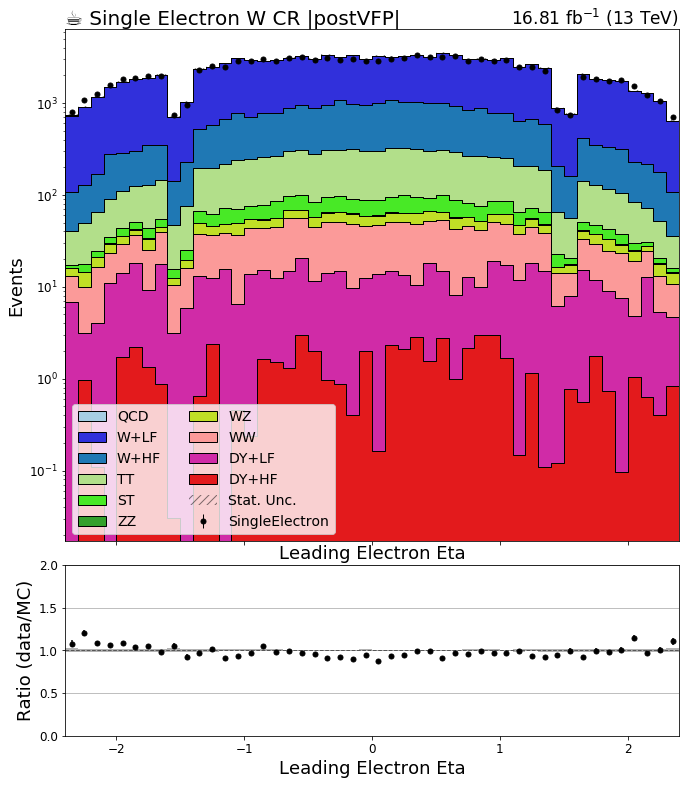

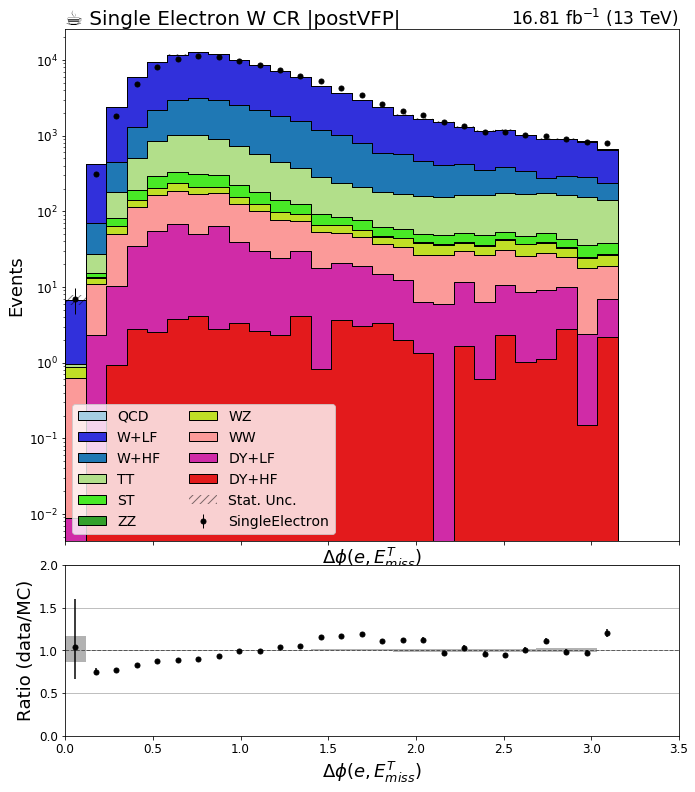

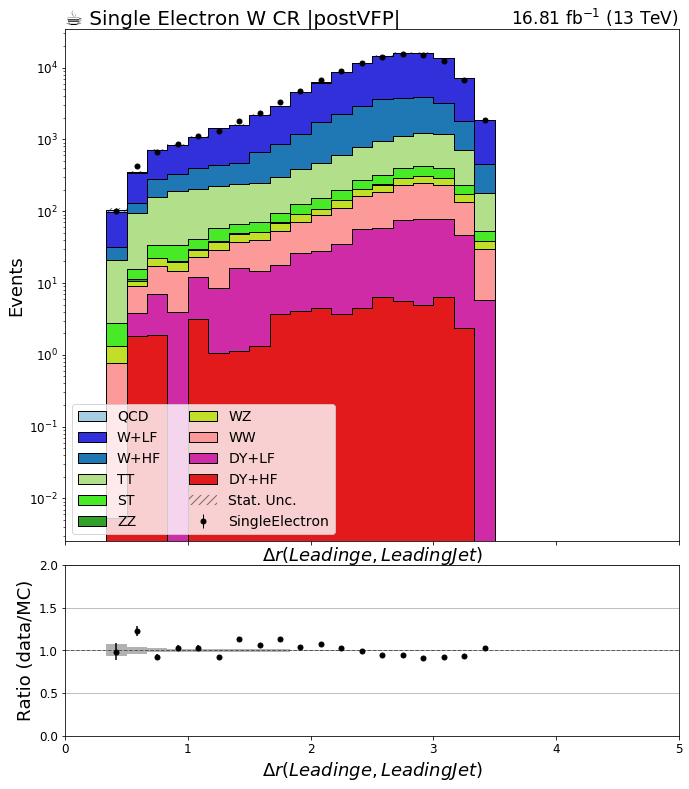

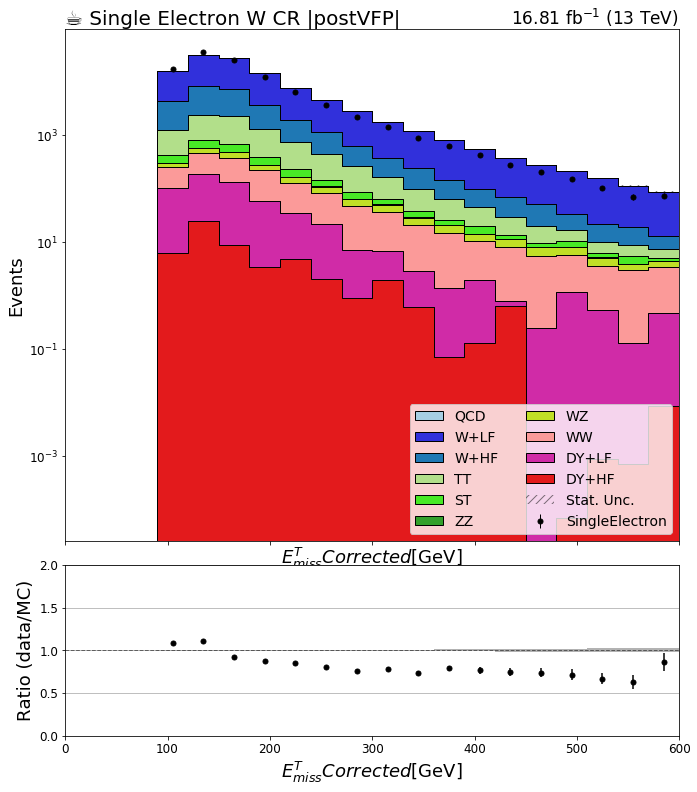

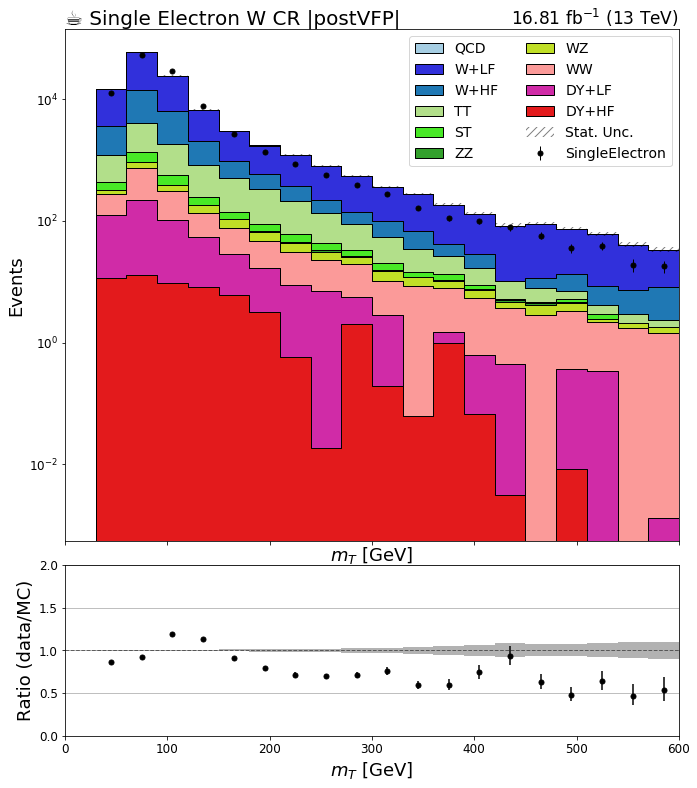

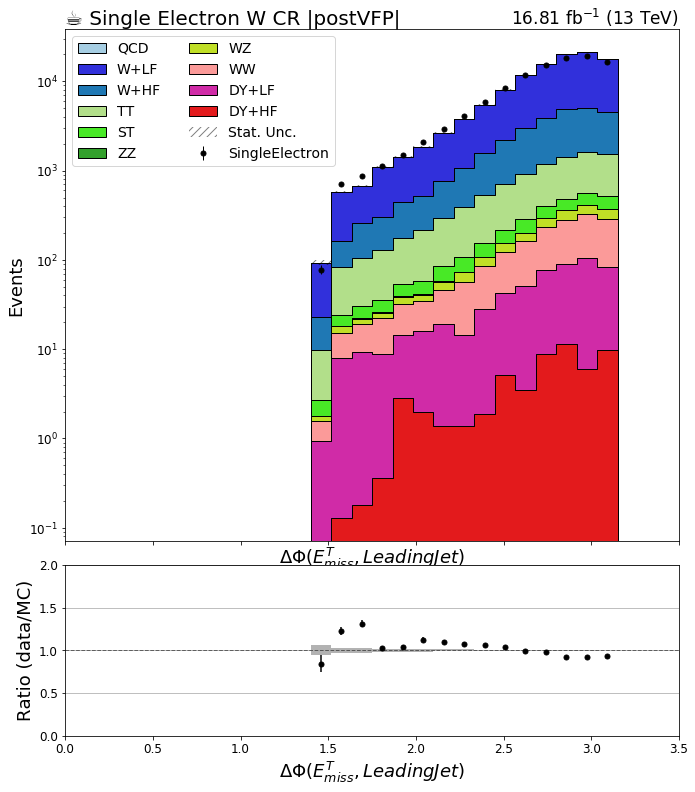

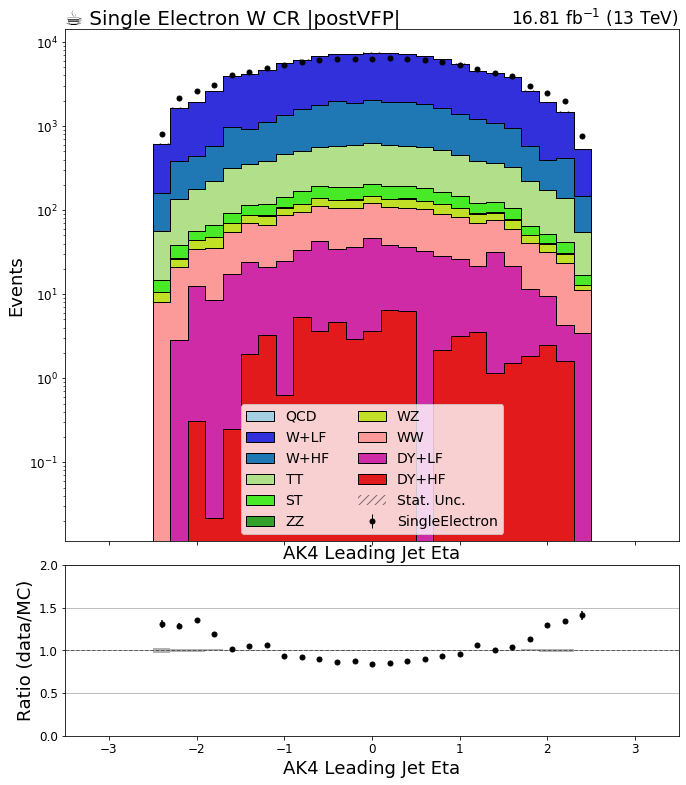

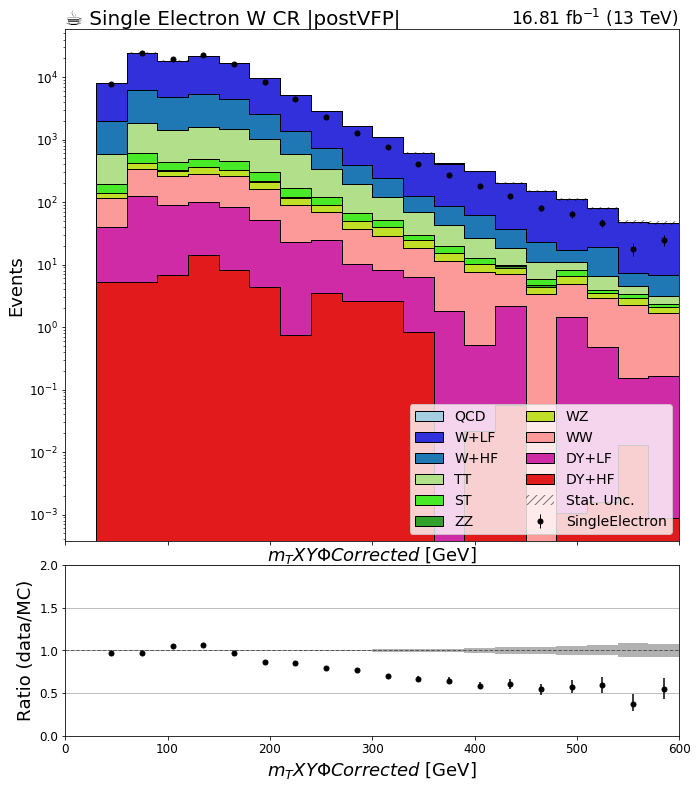

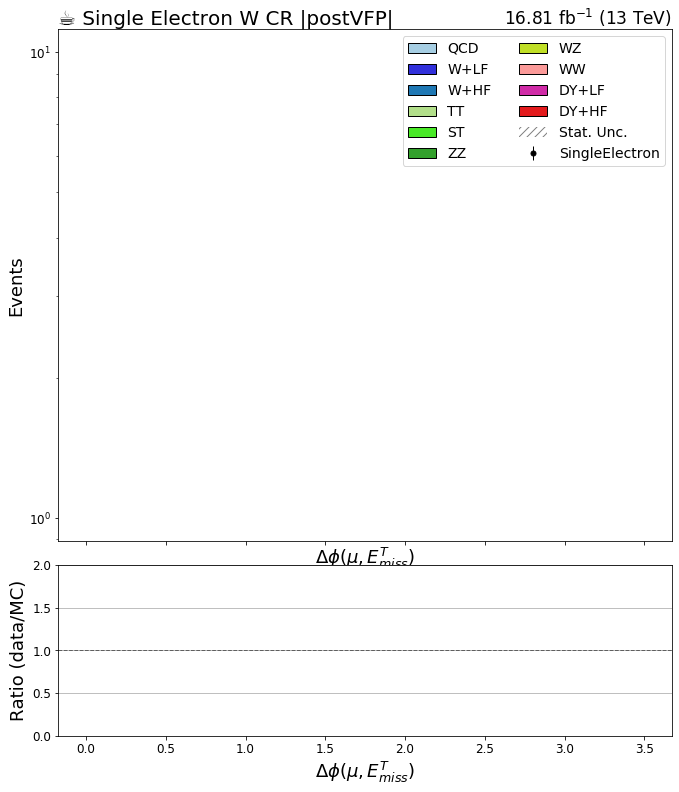

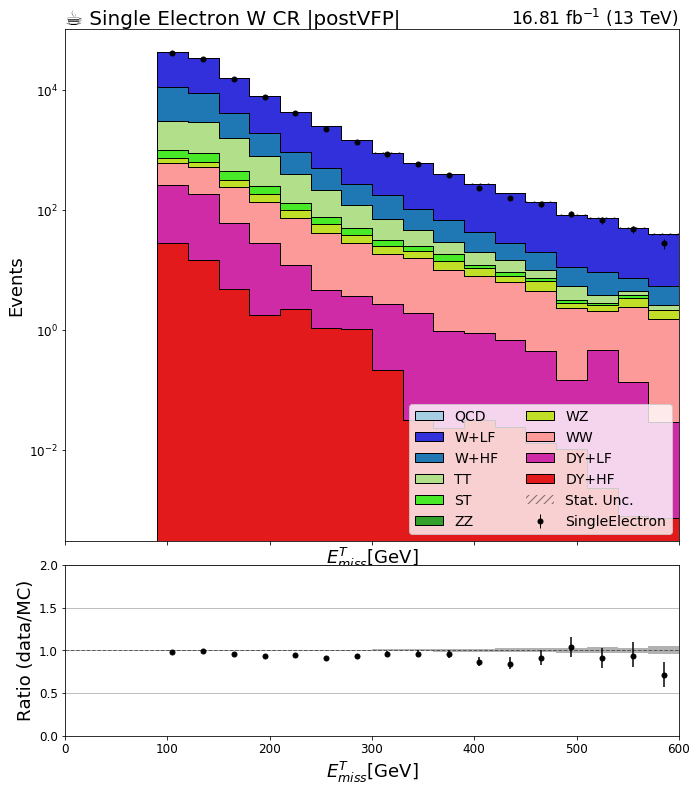

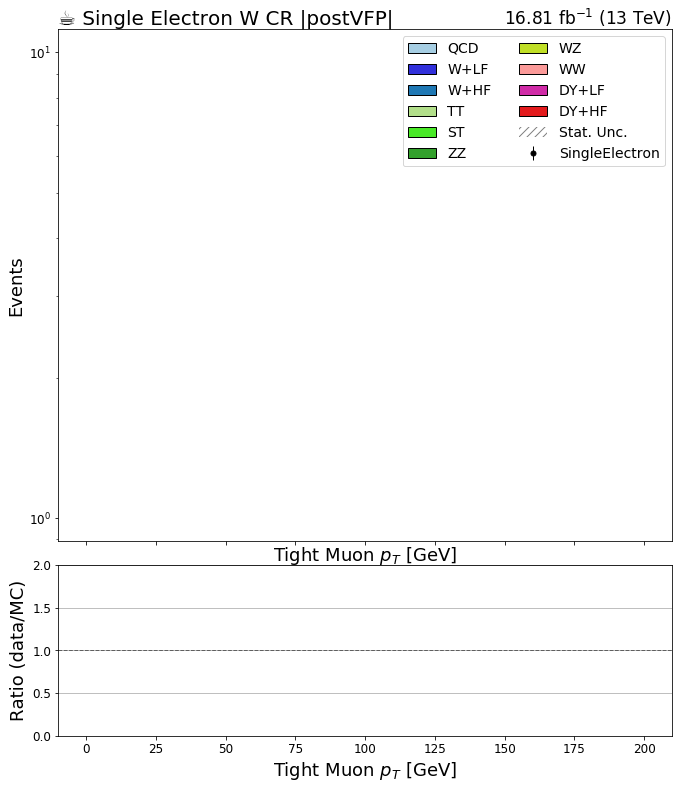

In [8]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2016'
region = 'wjete'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('region',j).sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]]+' |postVFP|', fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"16.81 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic_preVFP'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic_preVFP'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

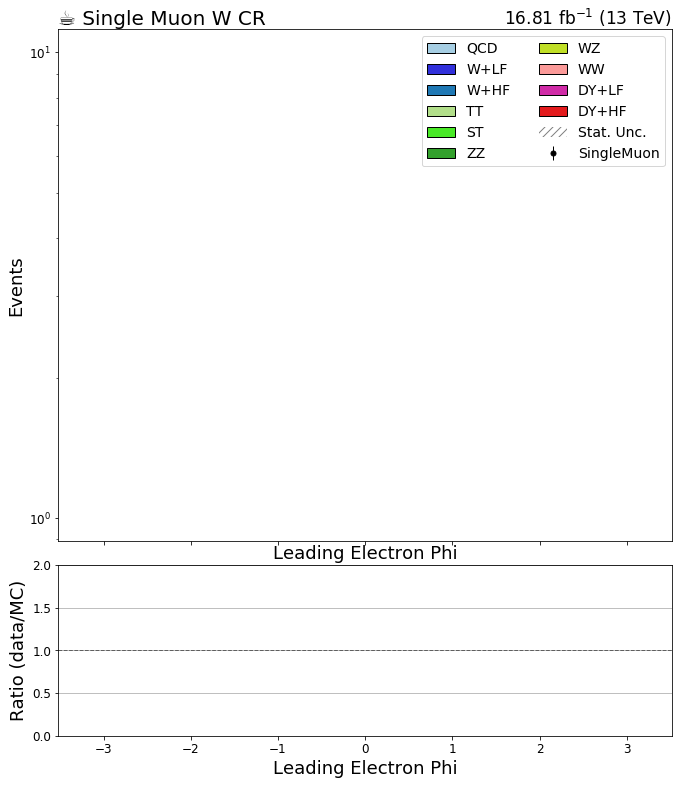

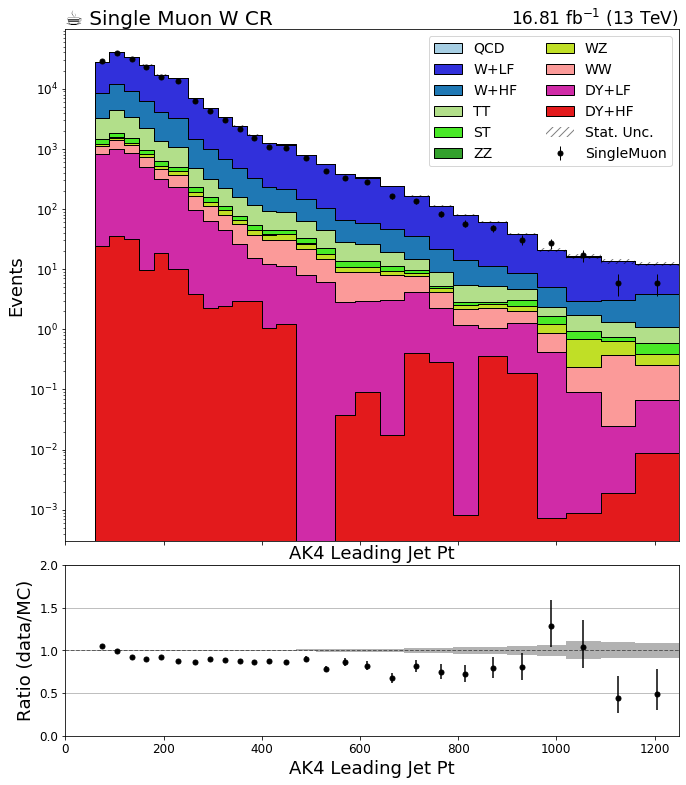

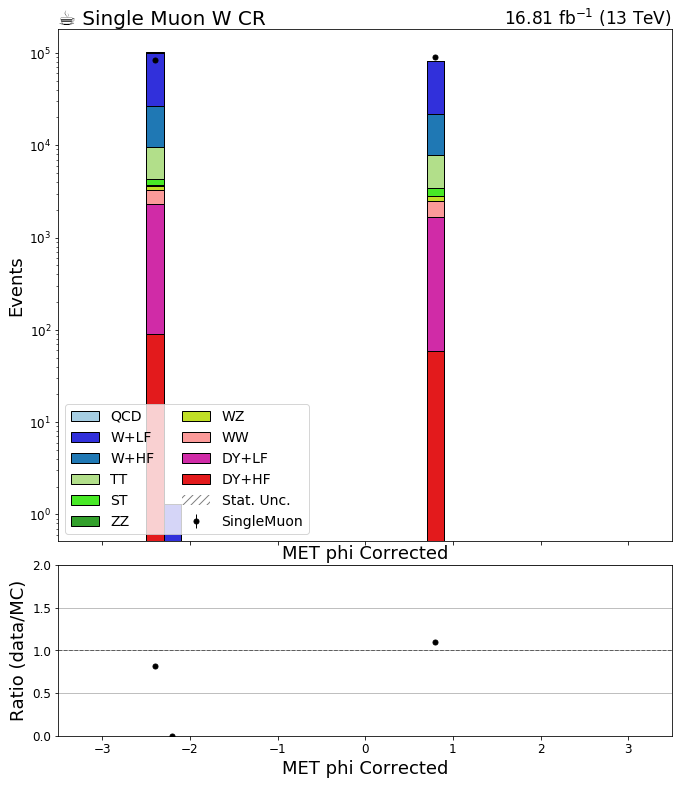

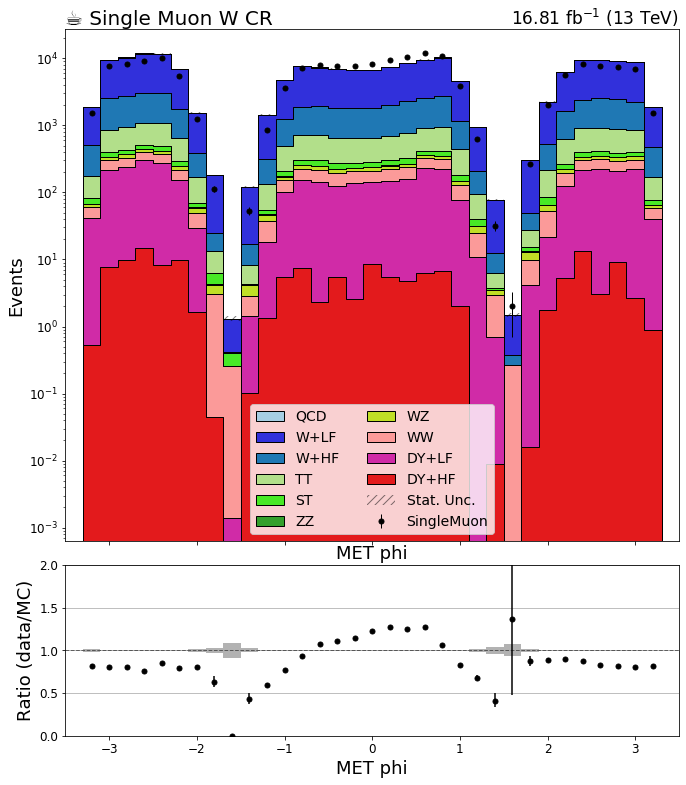

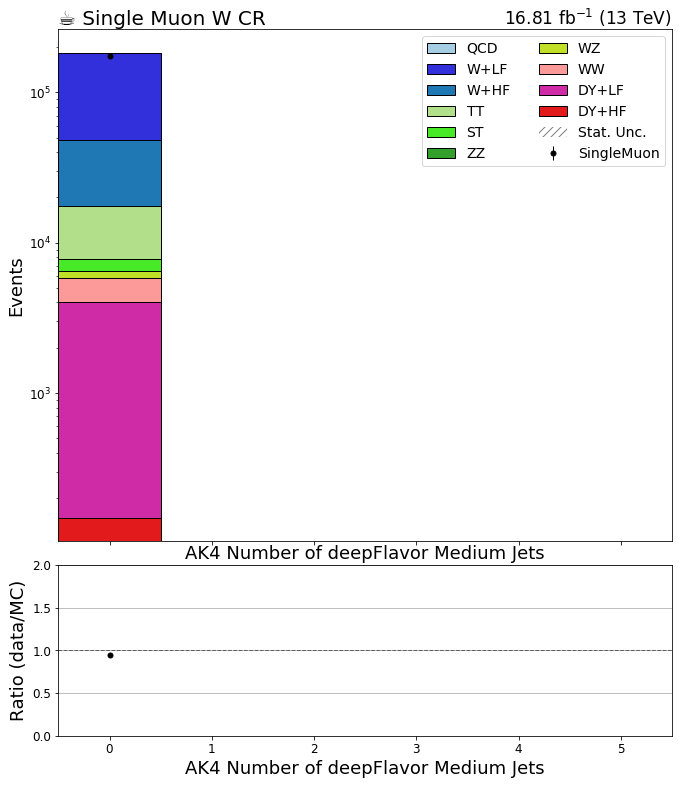

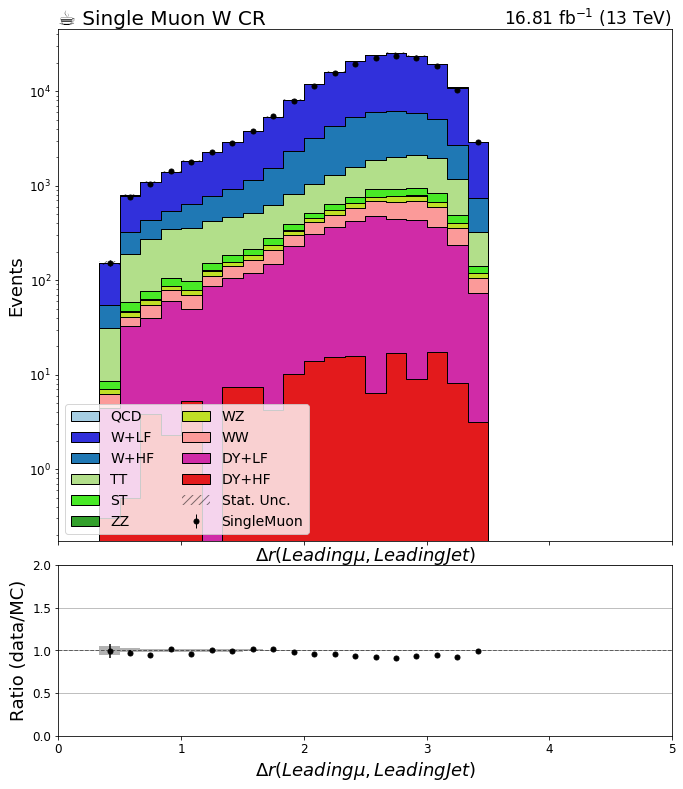

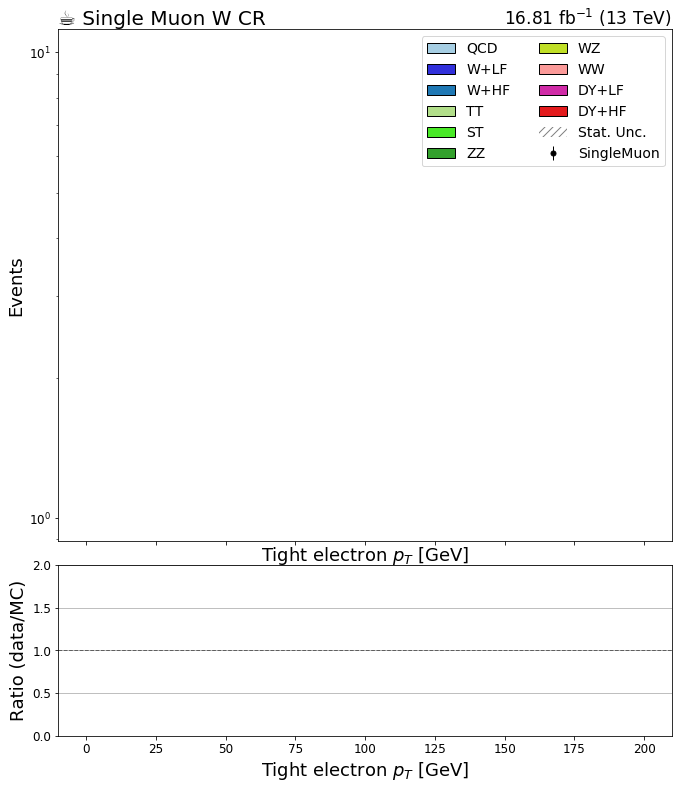

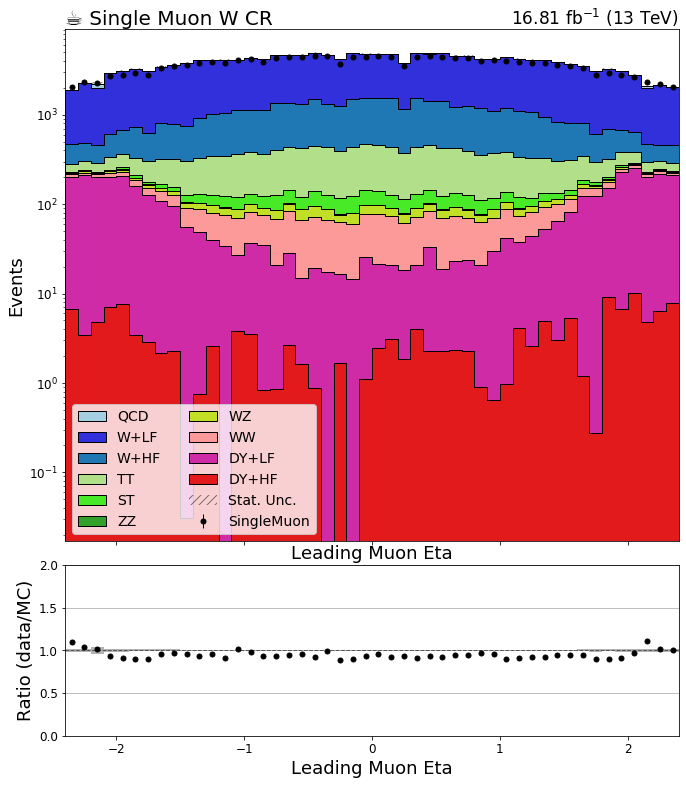

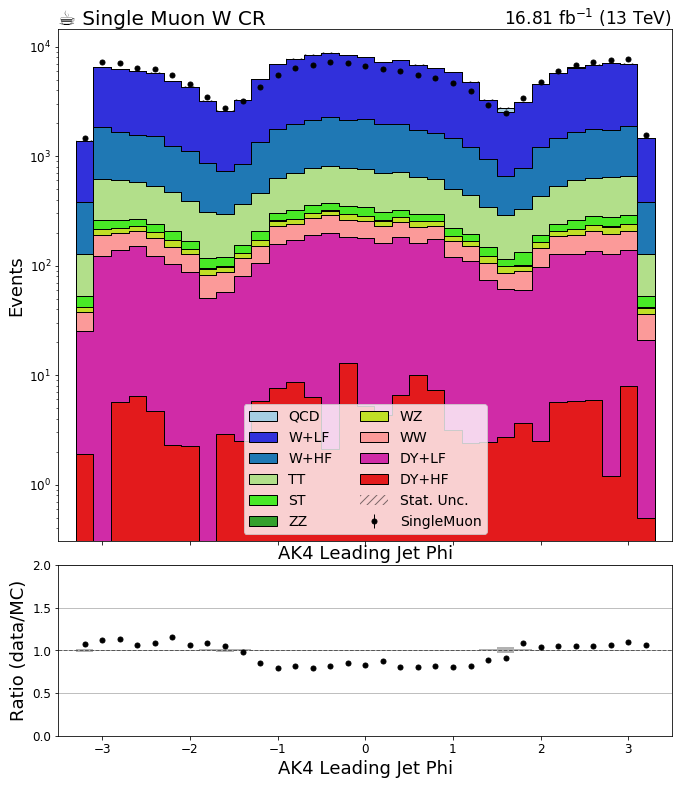

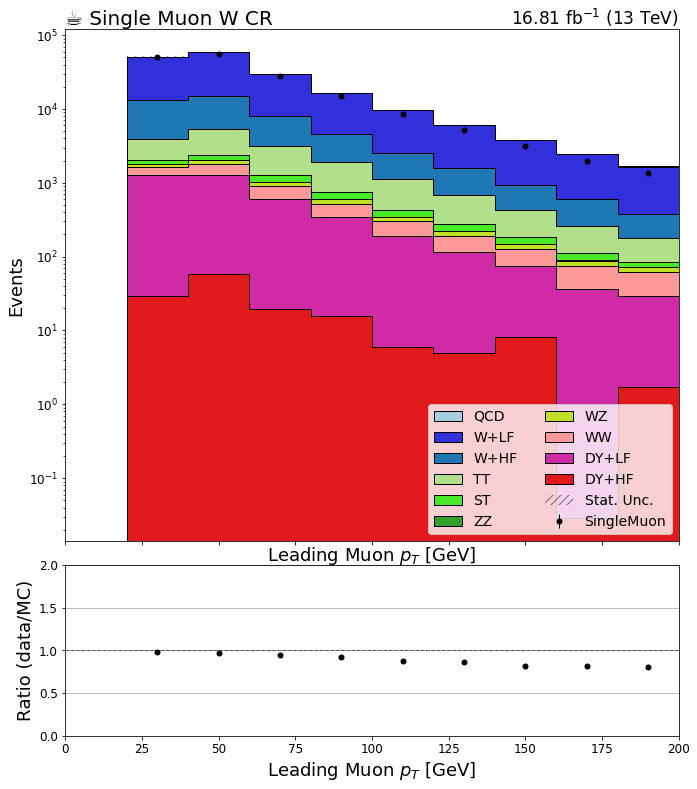

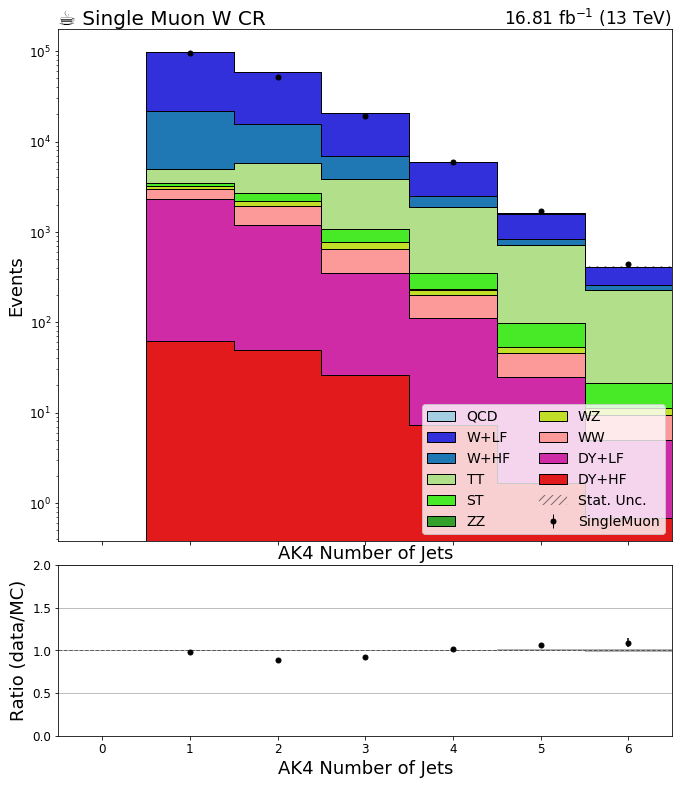

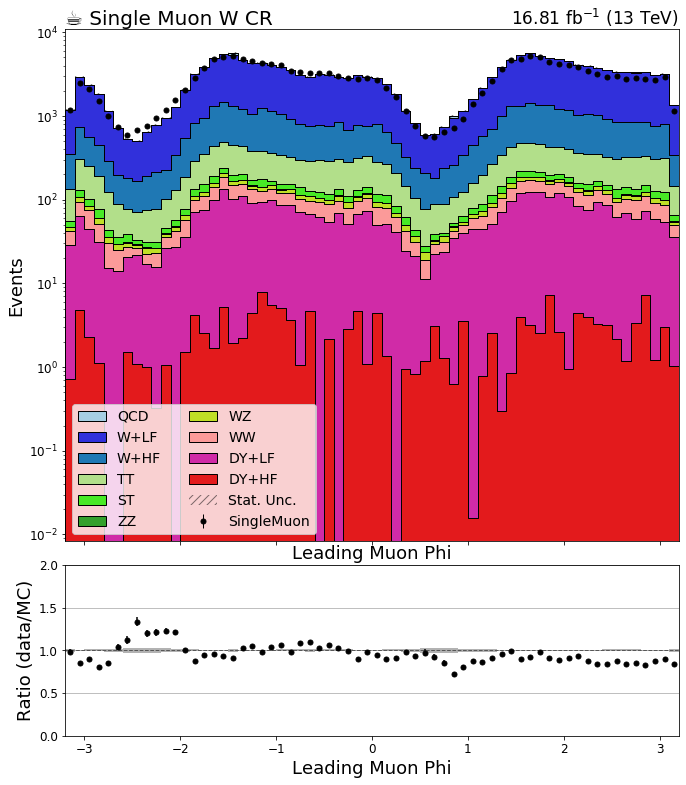

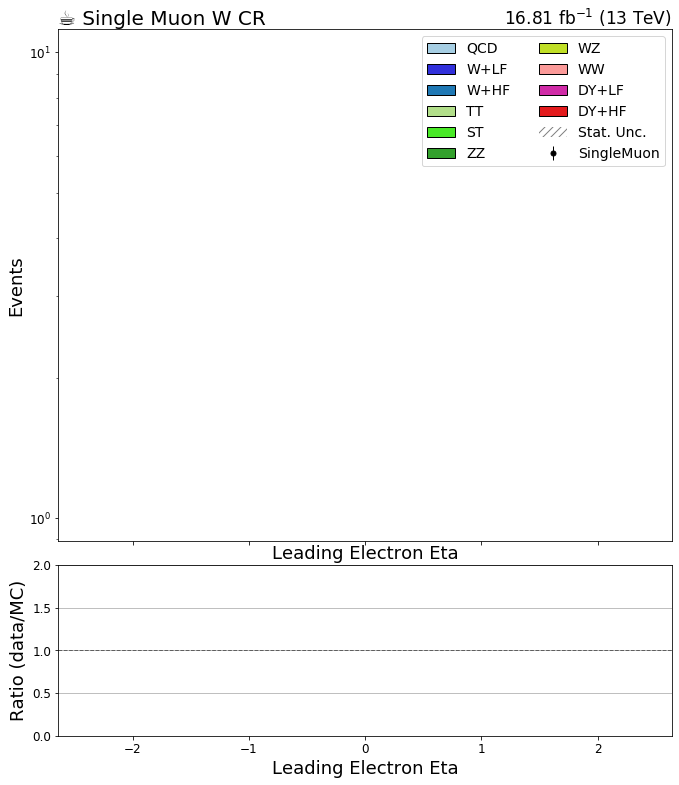

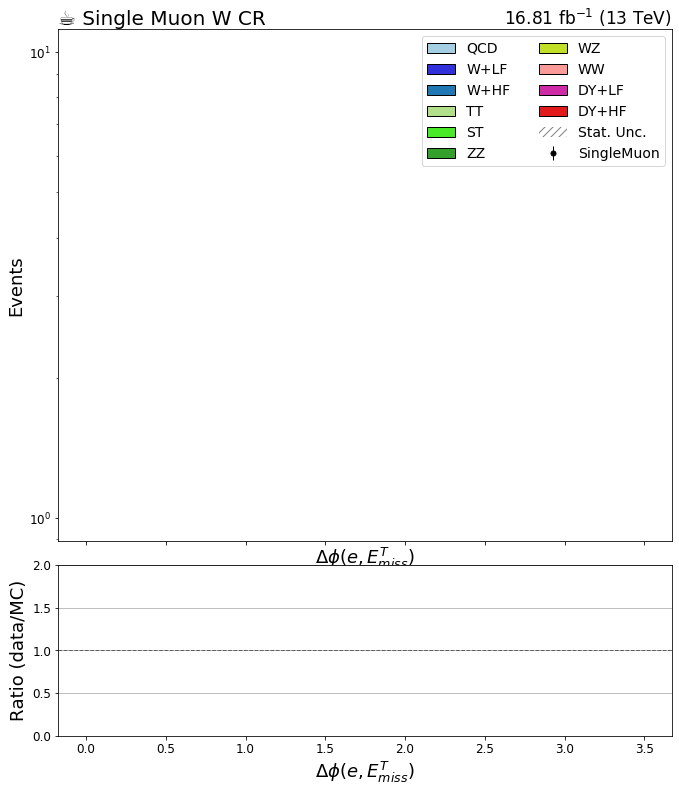

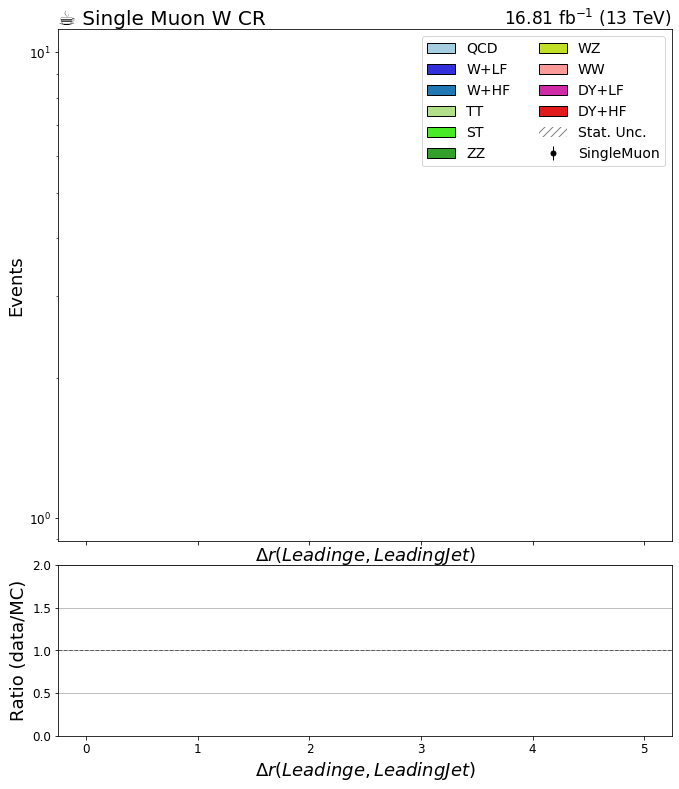

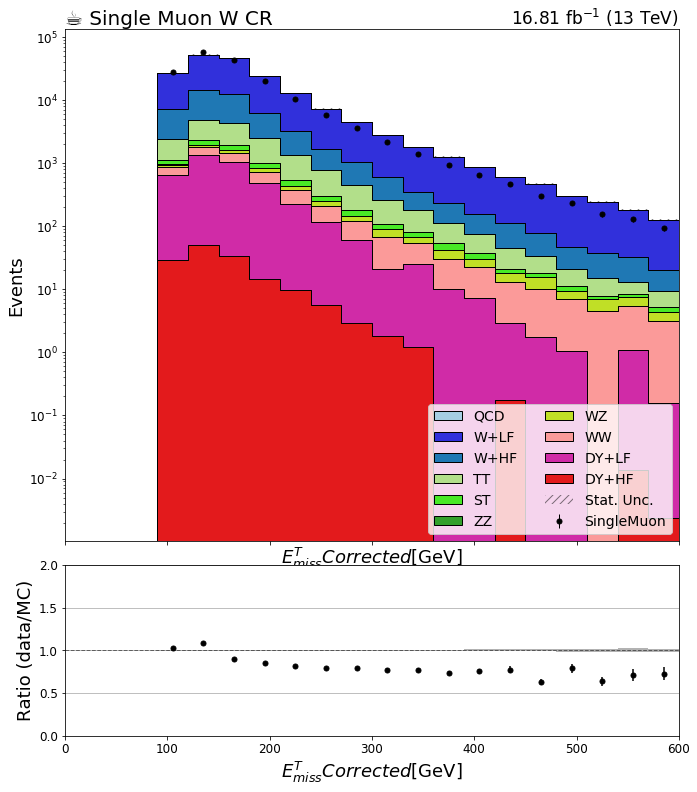

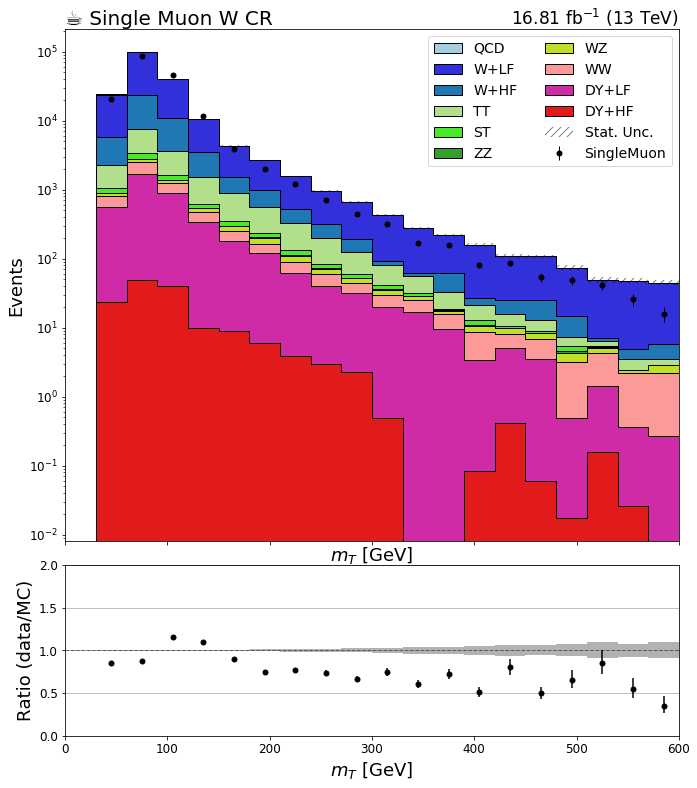

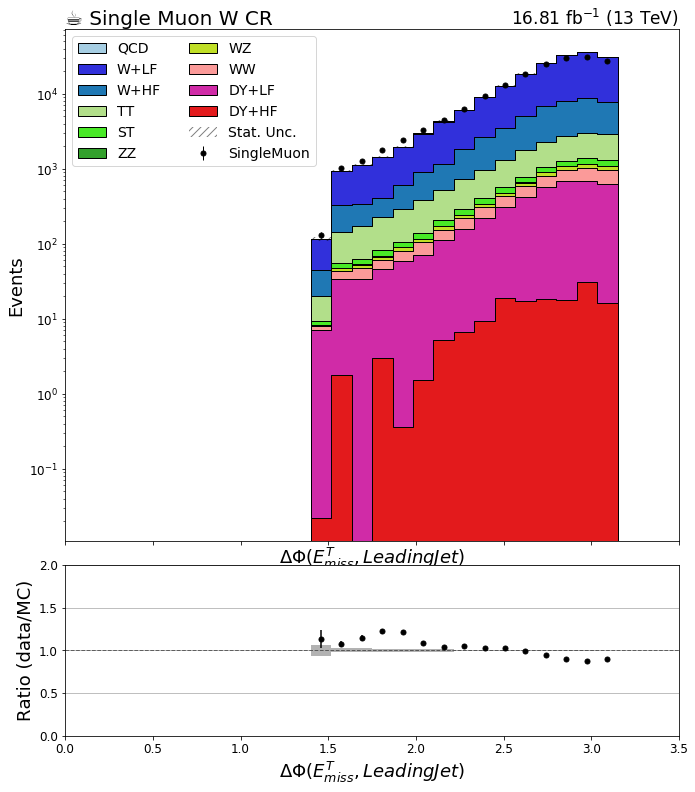

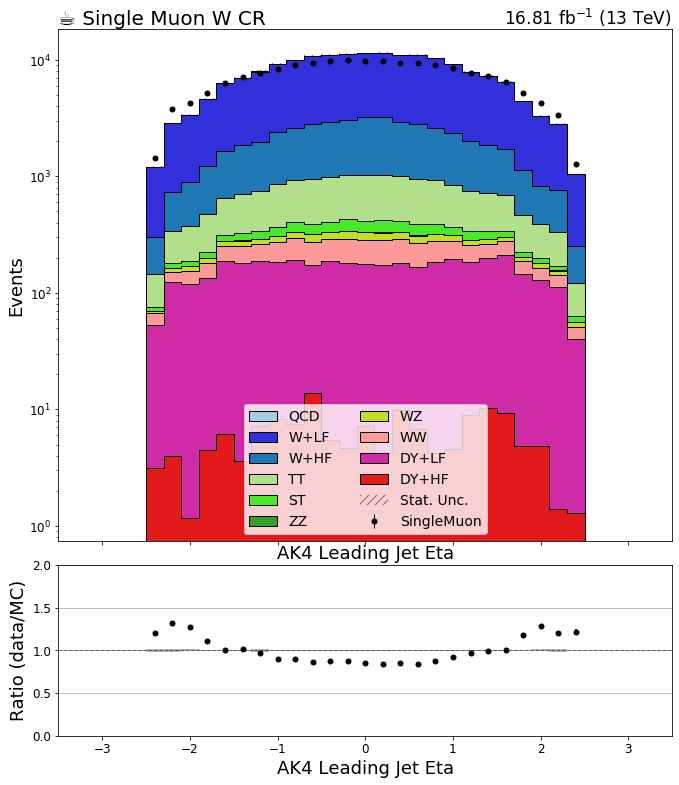

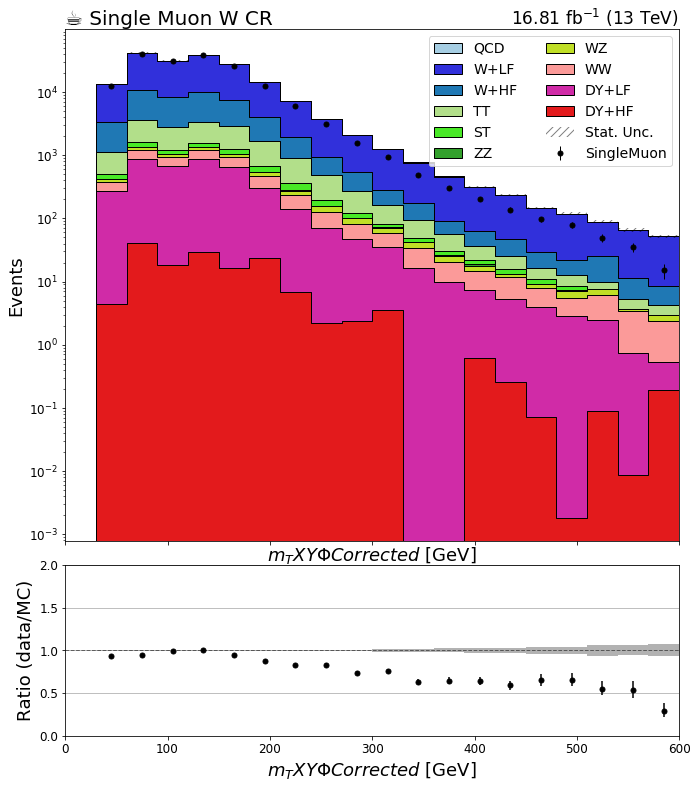

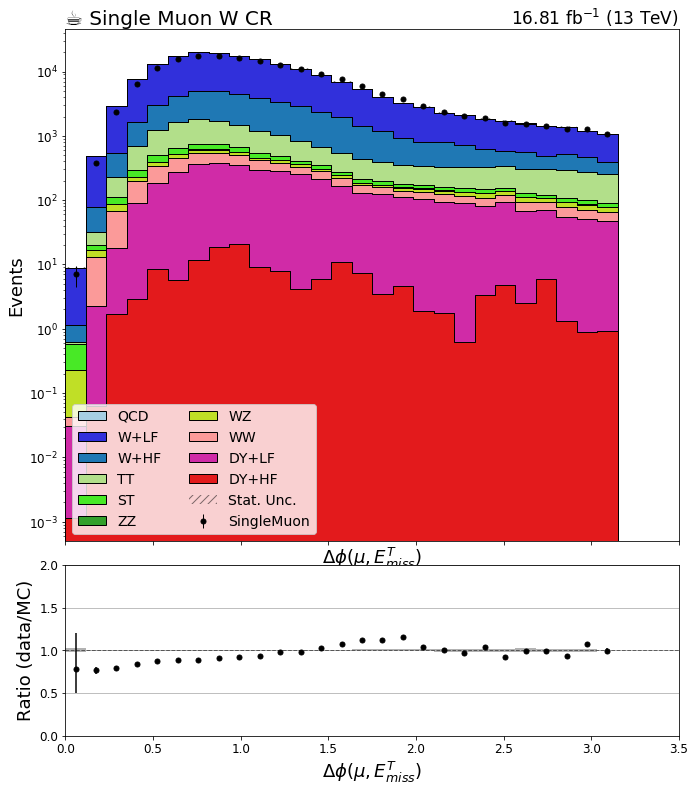

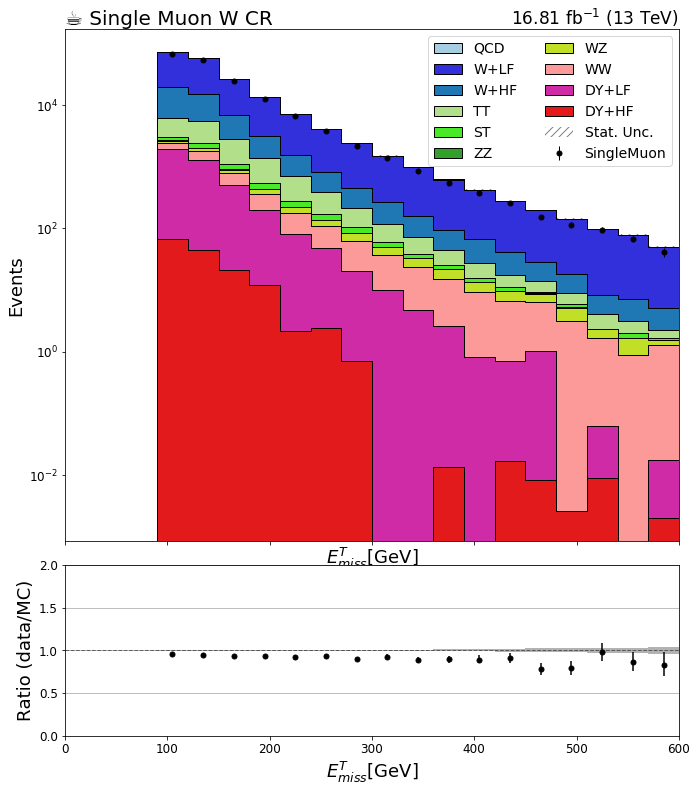

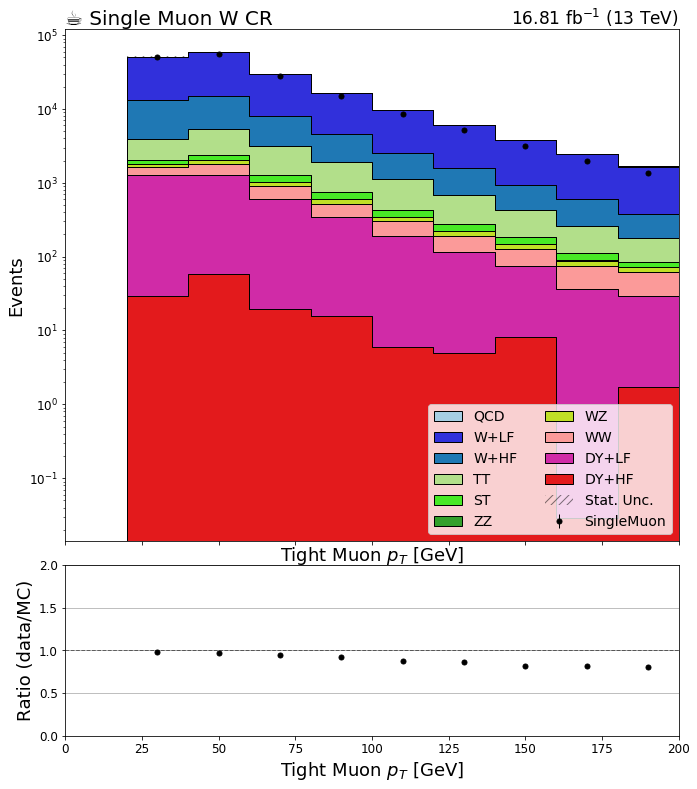

In [4]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2016'
region = 'wjetm'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('region',j).sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"16.81 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic_preVFP'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic_preVFP'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

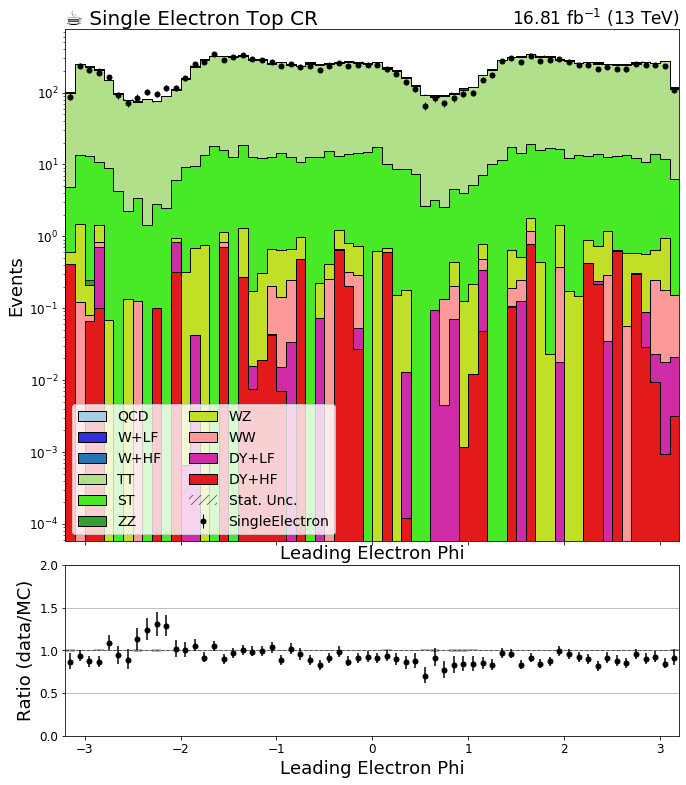

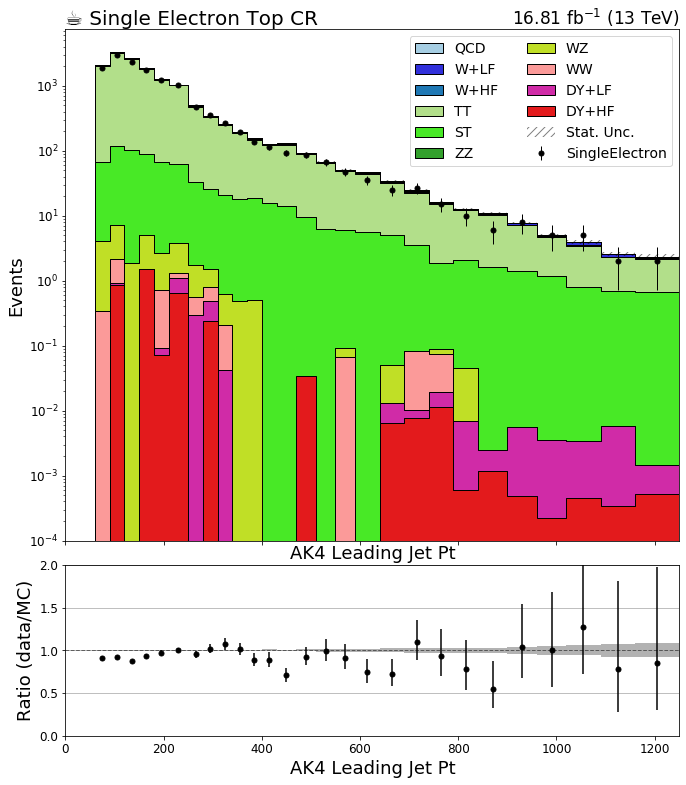

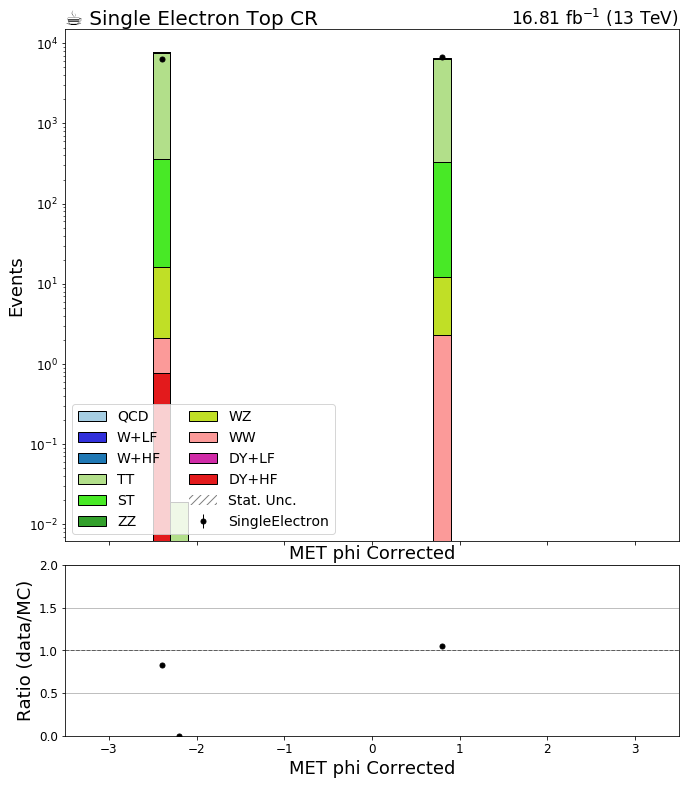

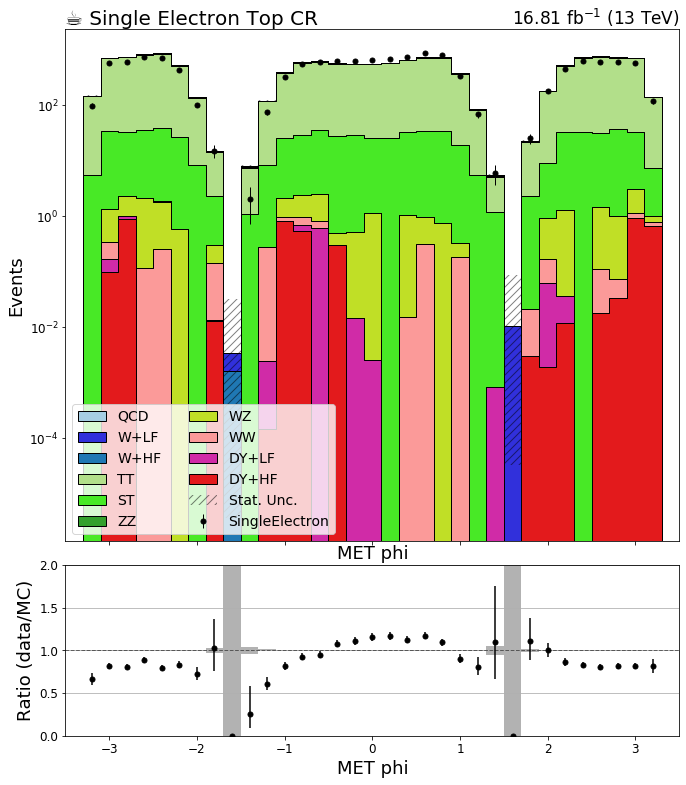

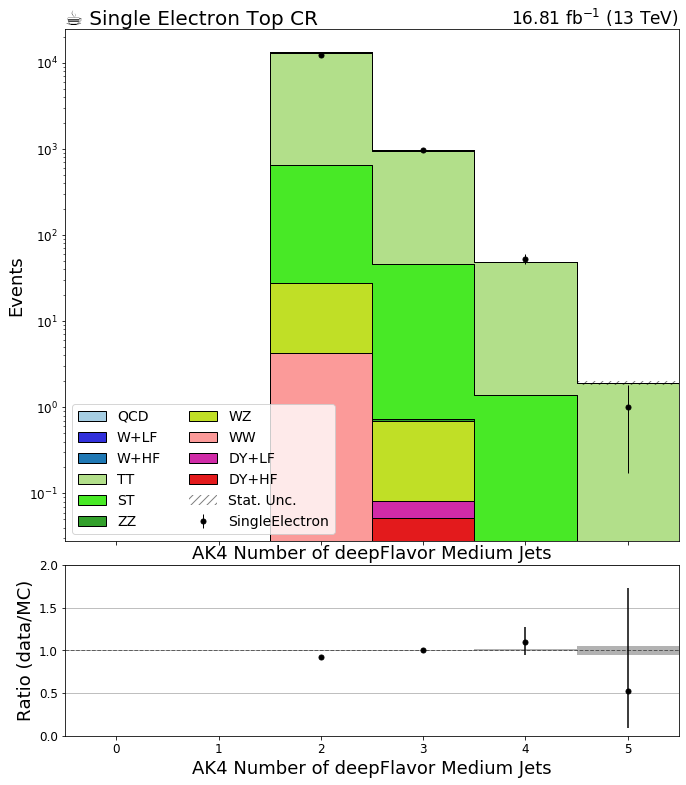

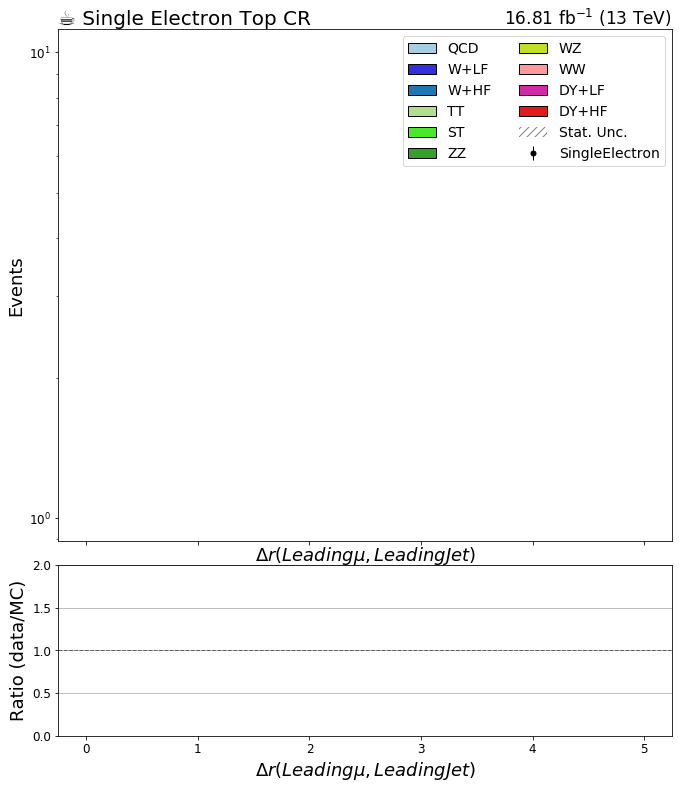

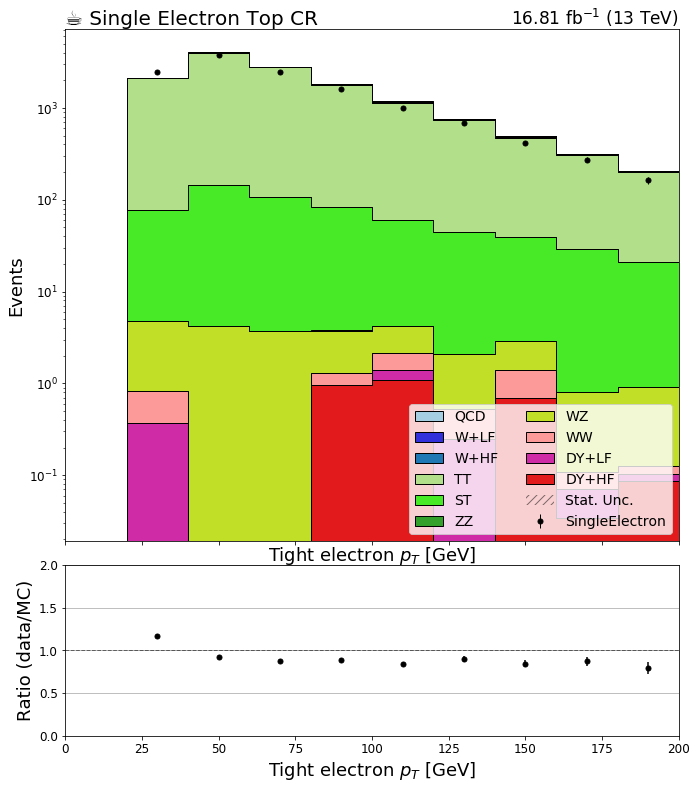

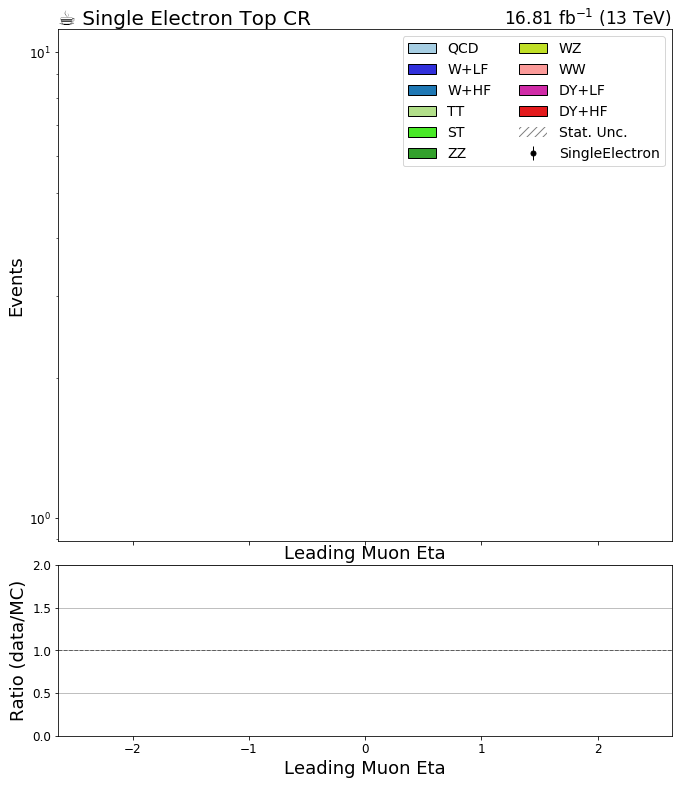

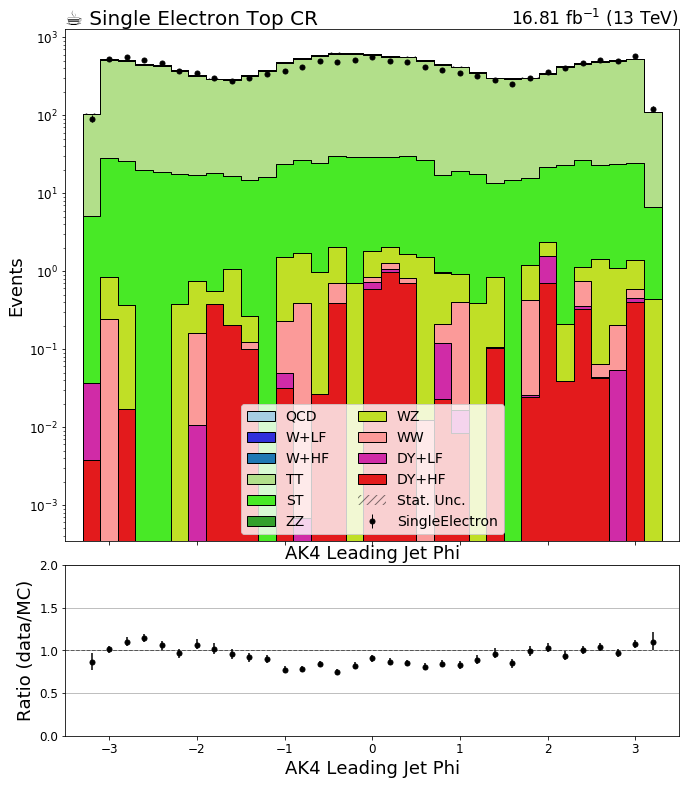

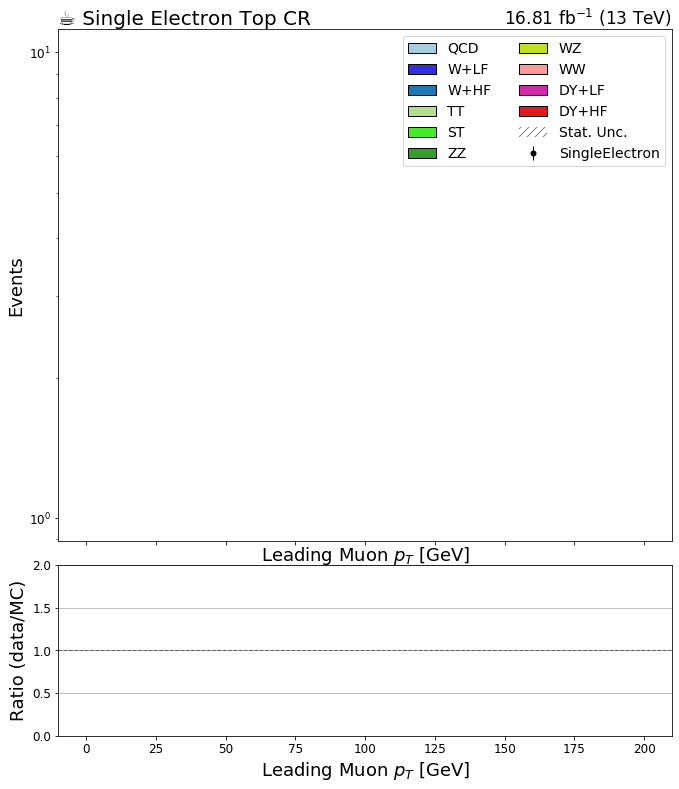

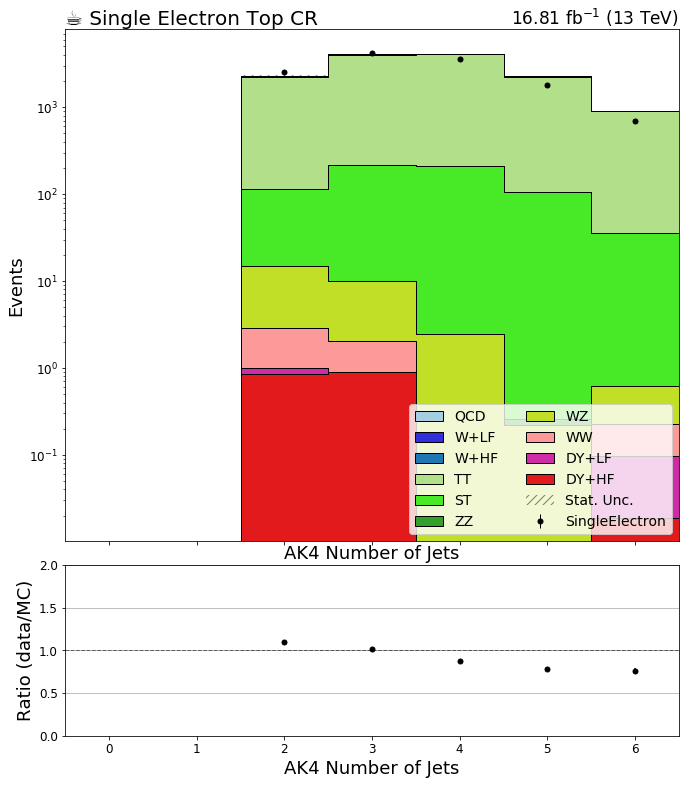

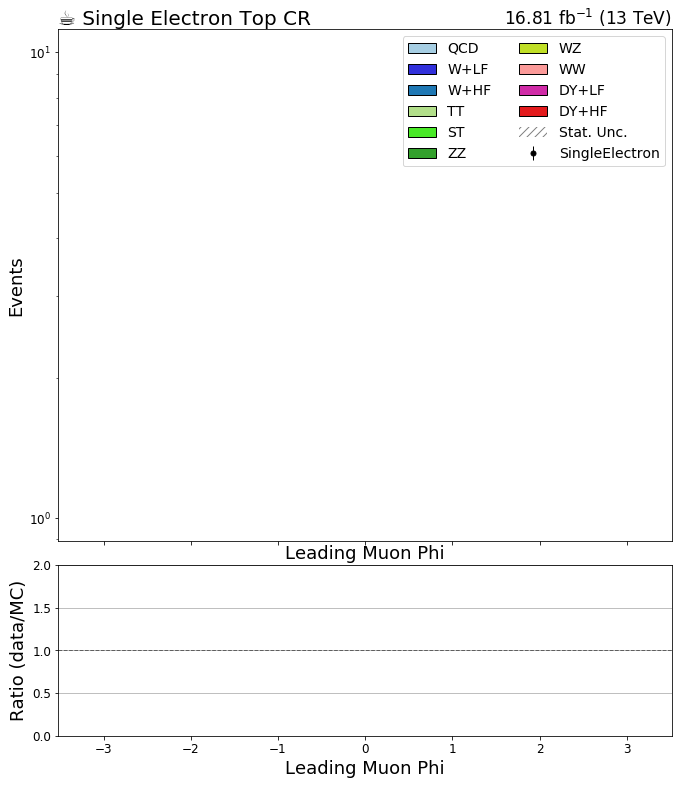

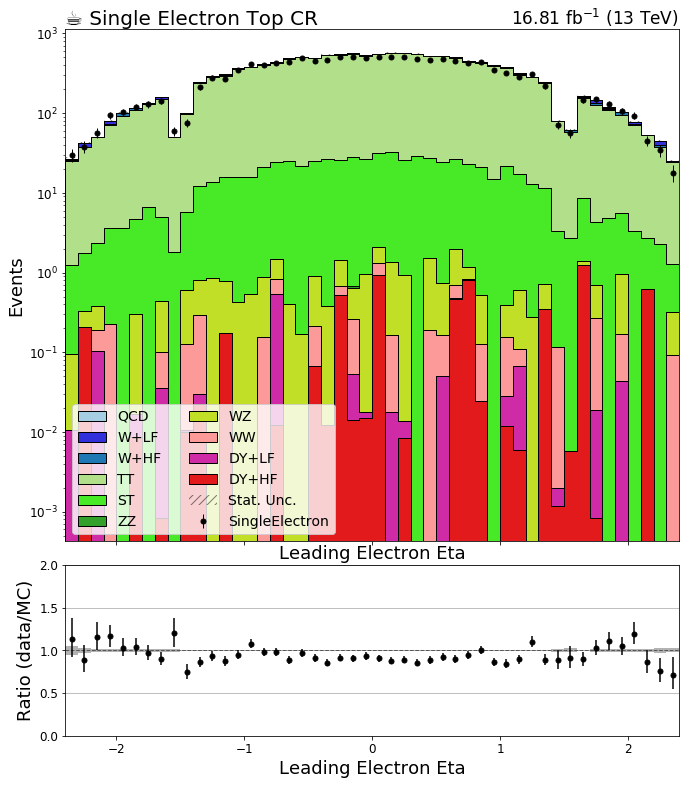

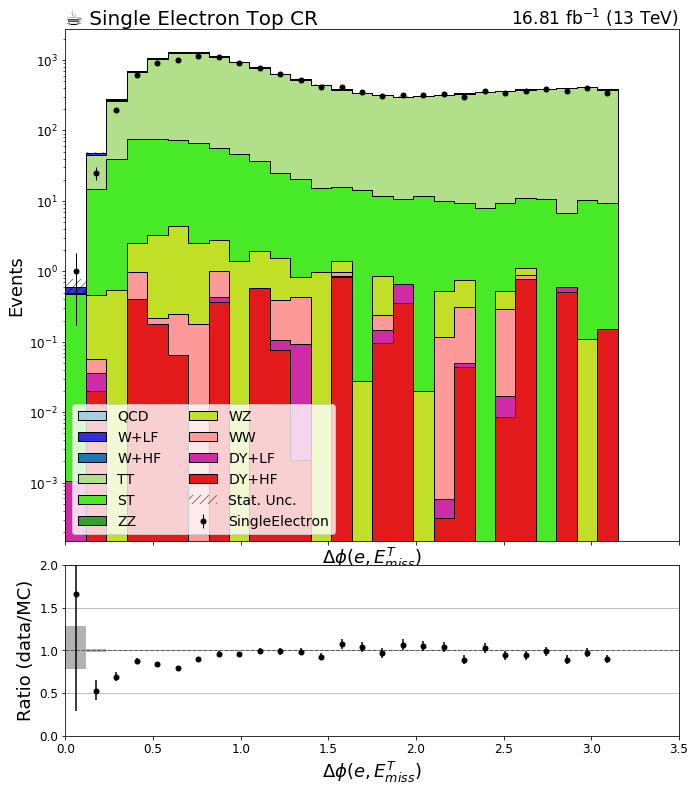

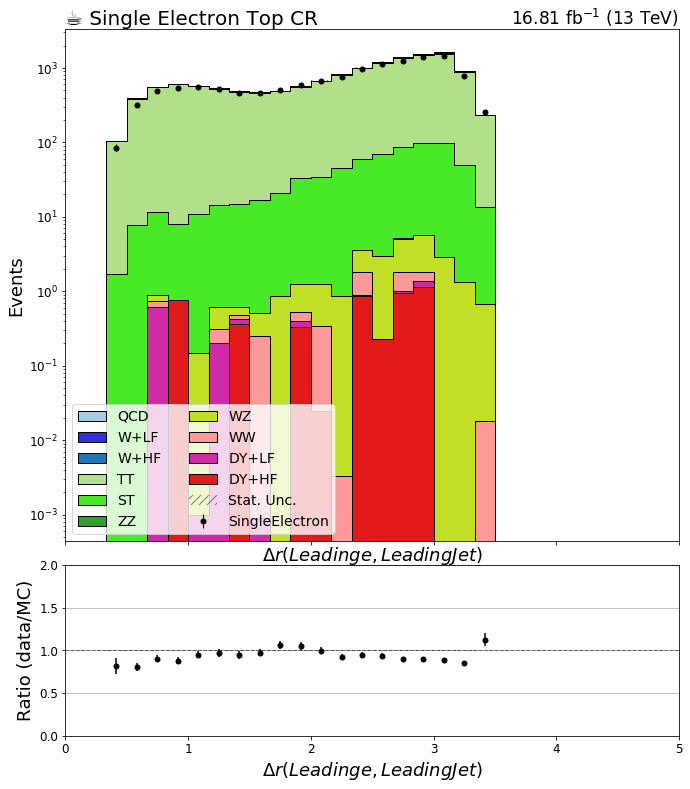

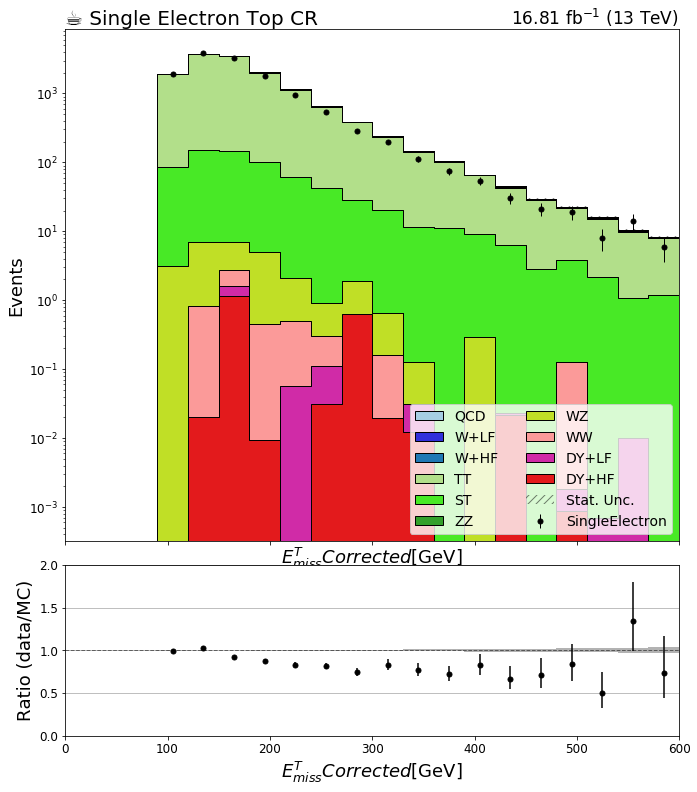

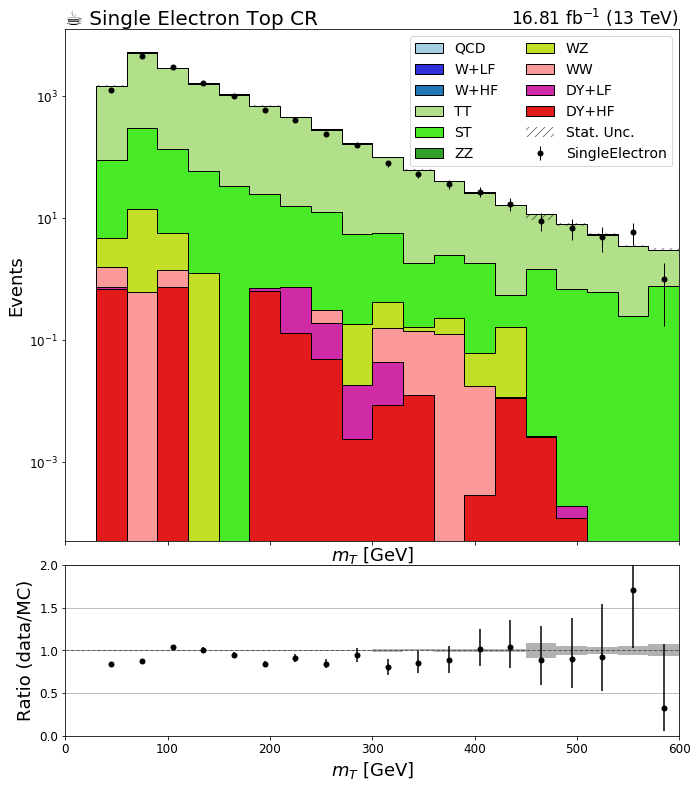

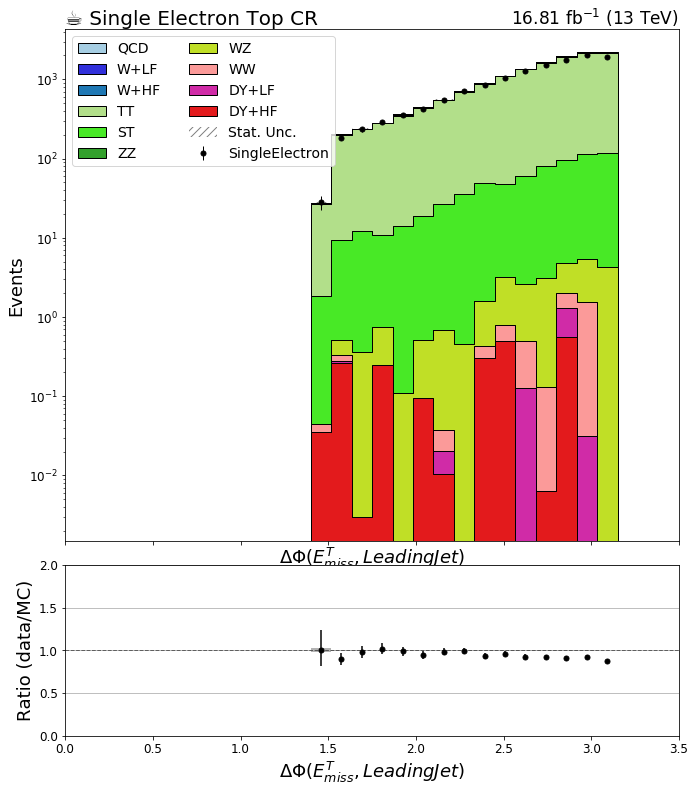

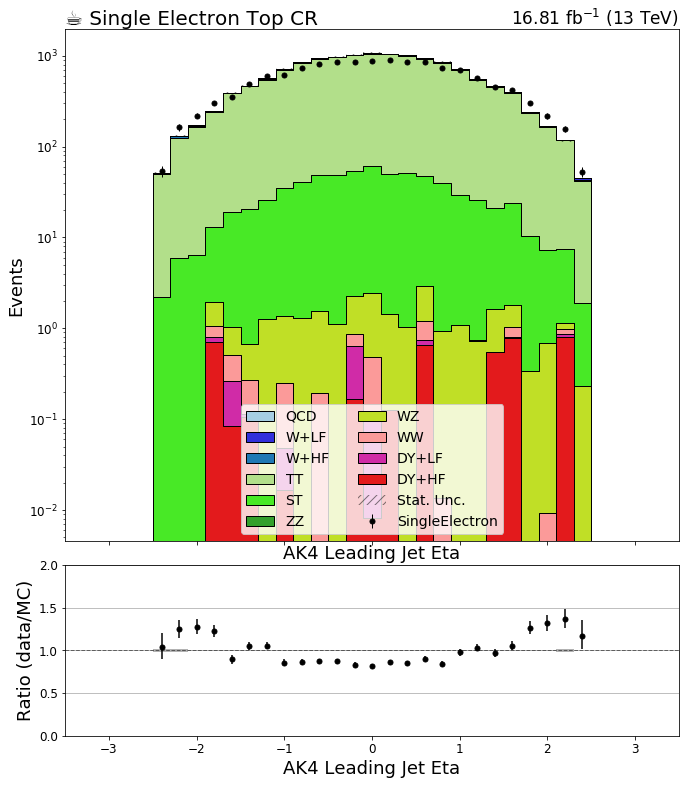

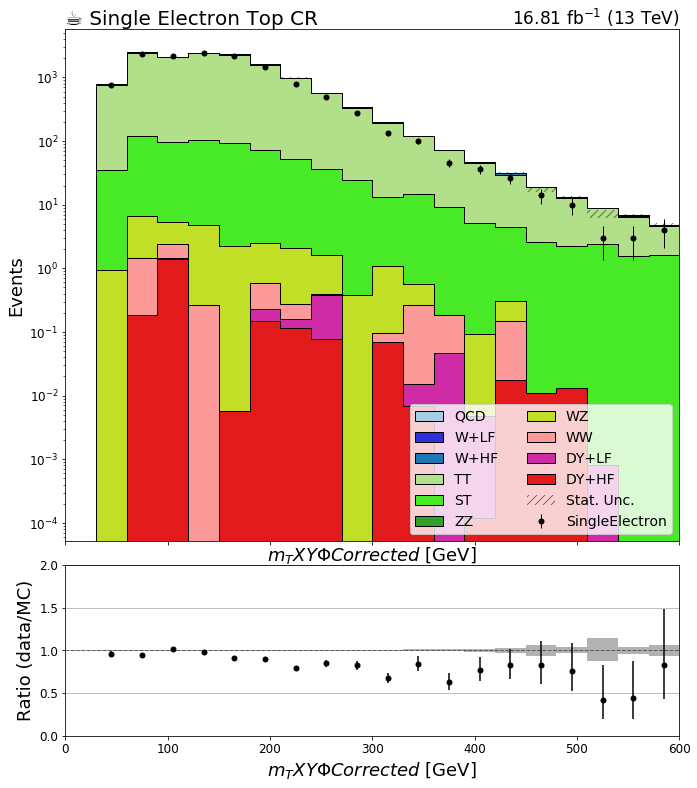

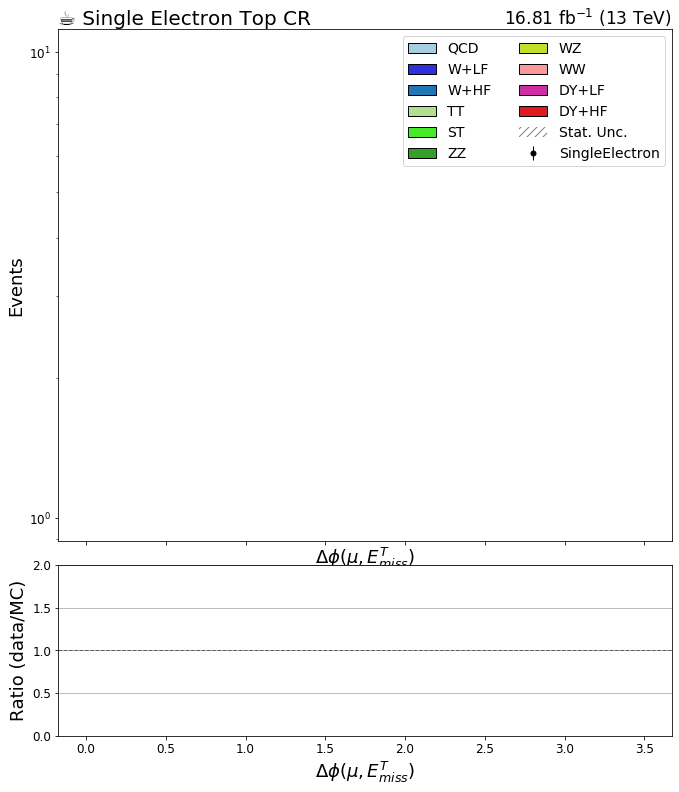

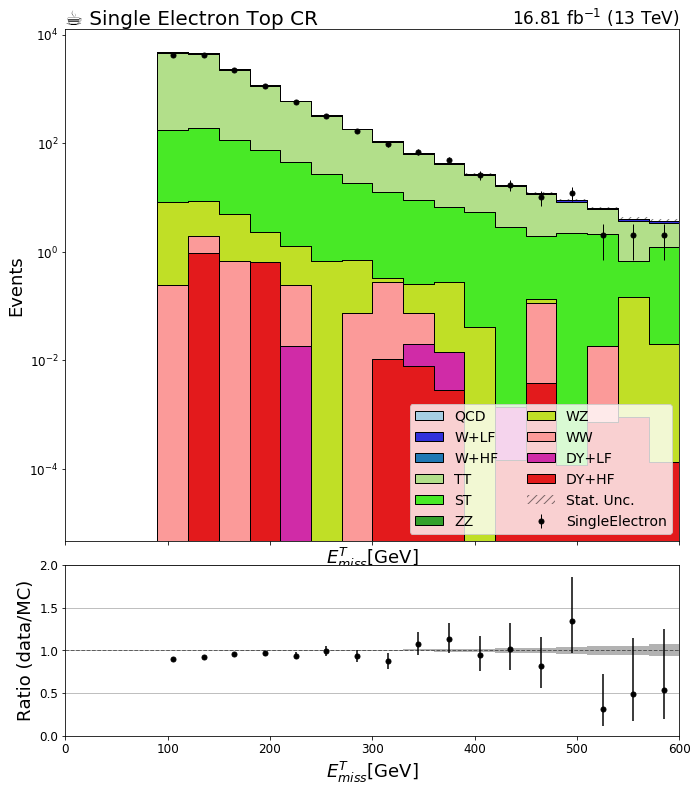

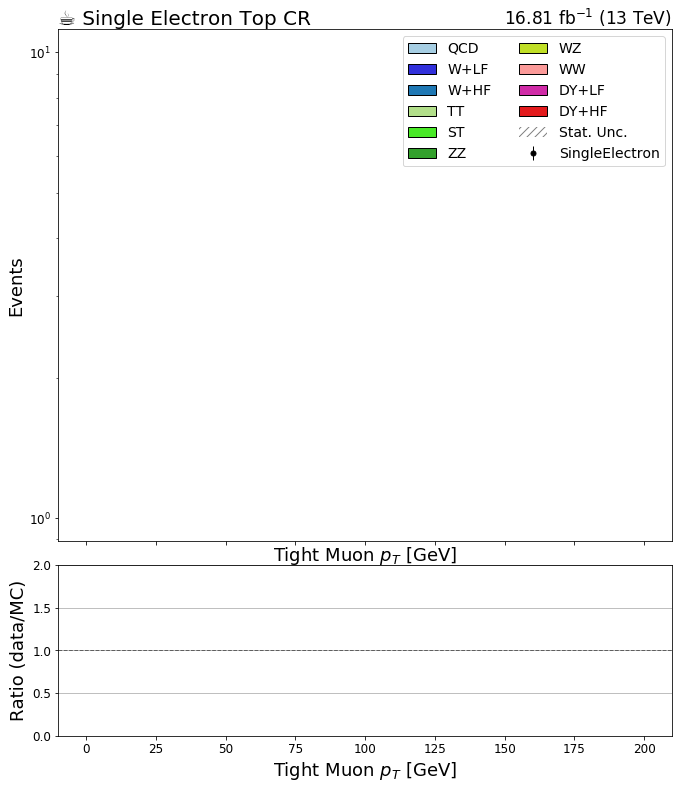

In [5]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2016'
region = 'ttbare'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('region',j).sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"16.81 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic_preVFP'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic_preVFP'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

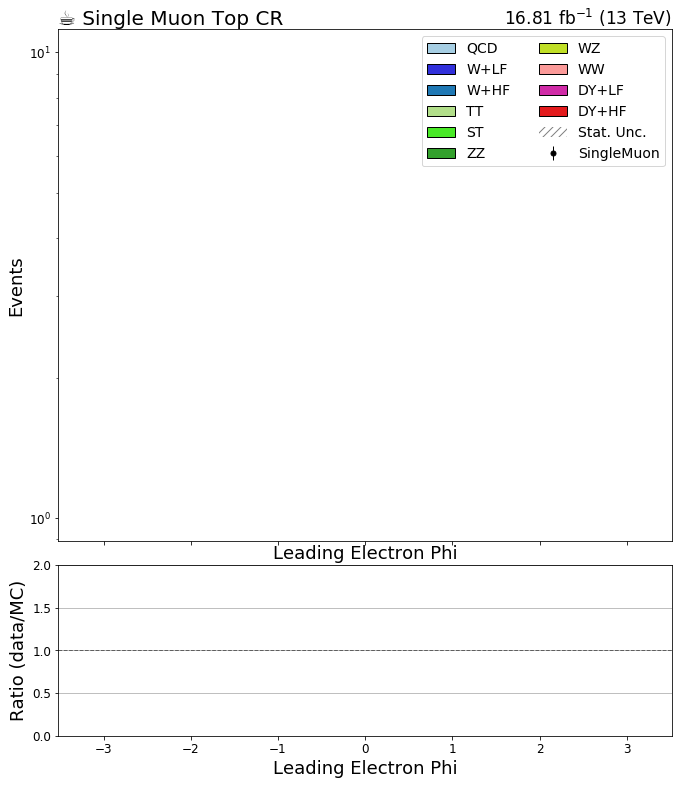

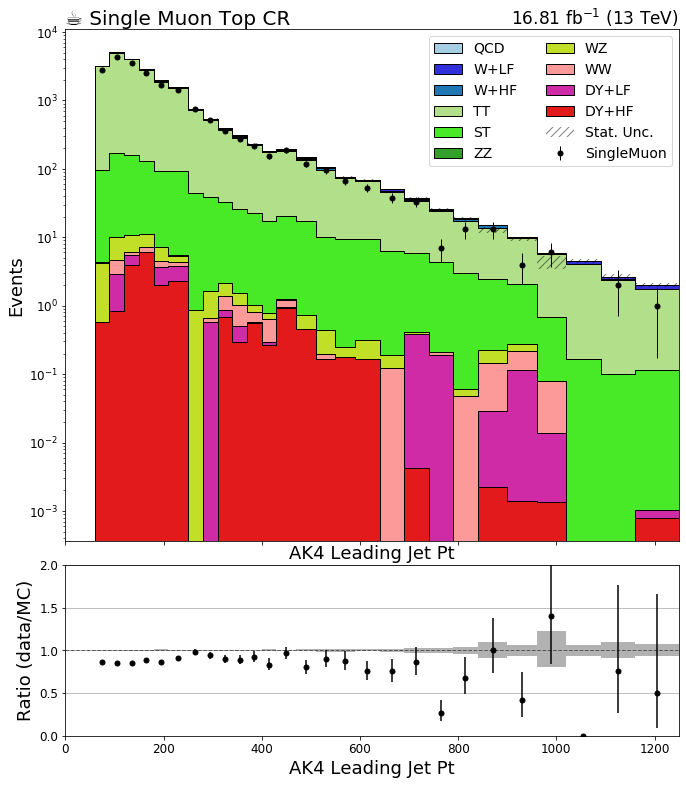

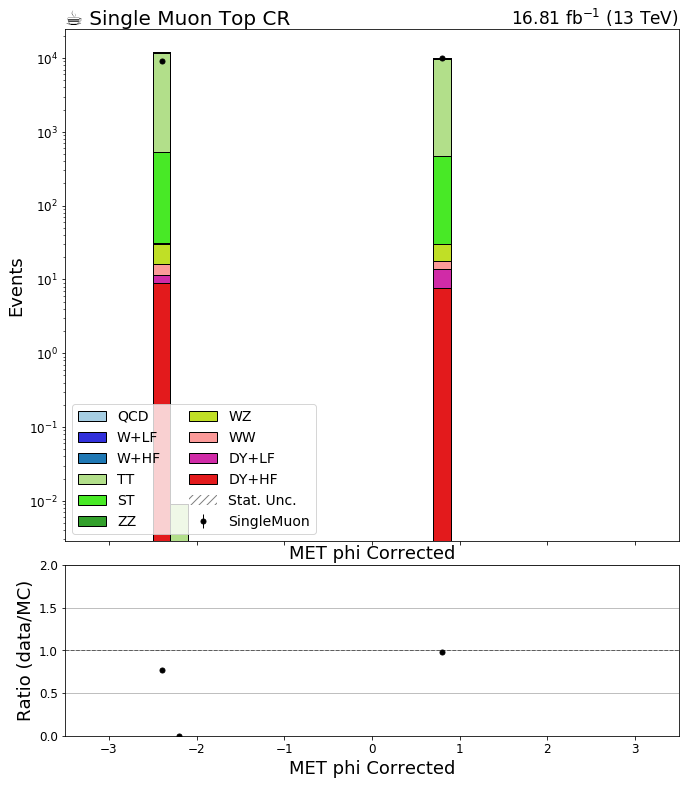

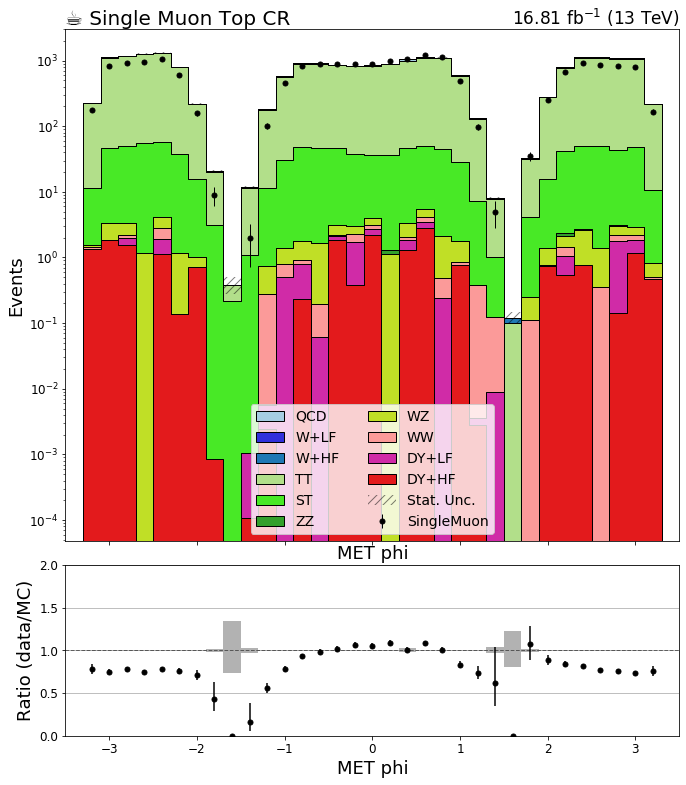

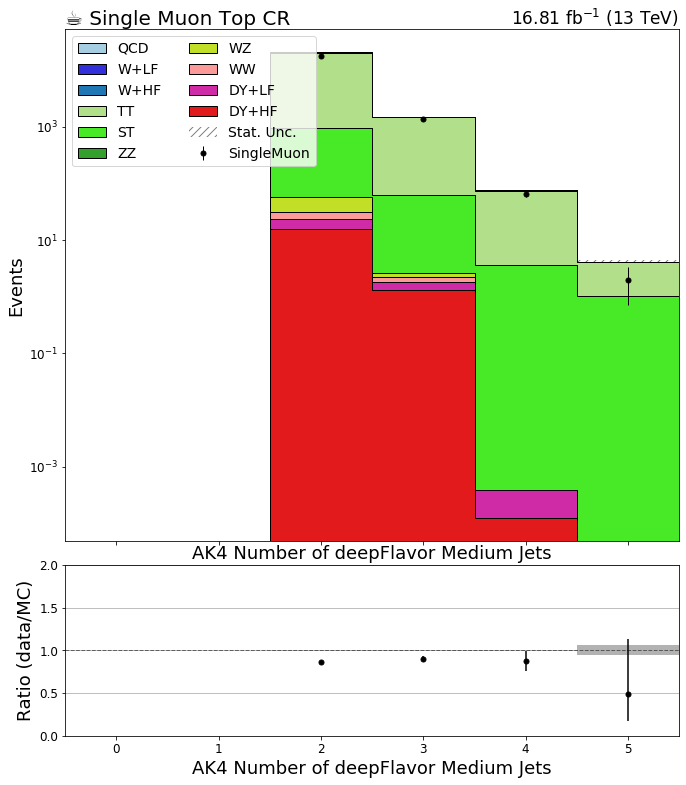

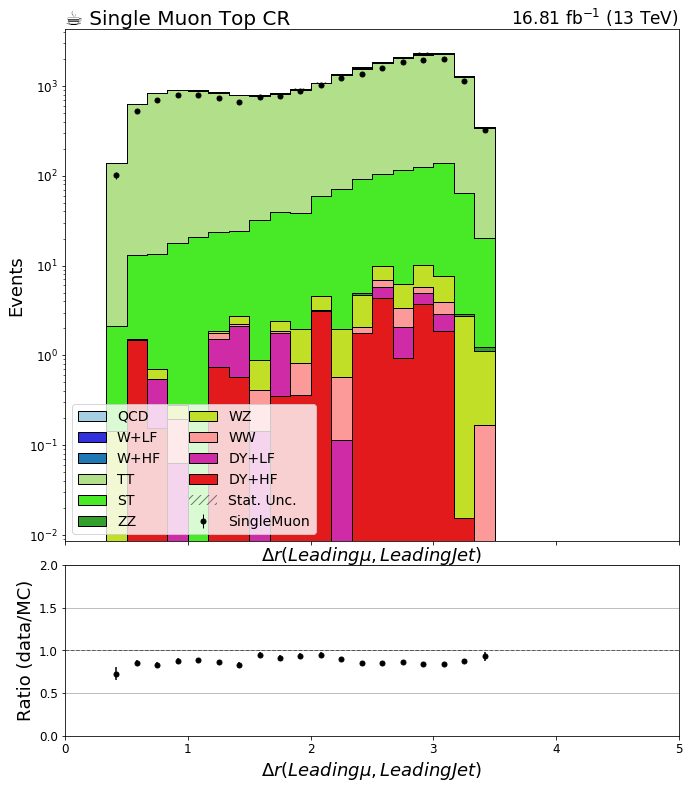

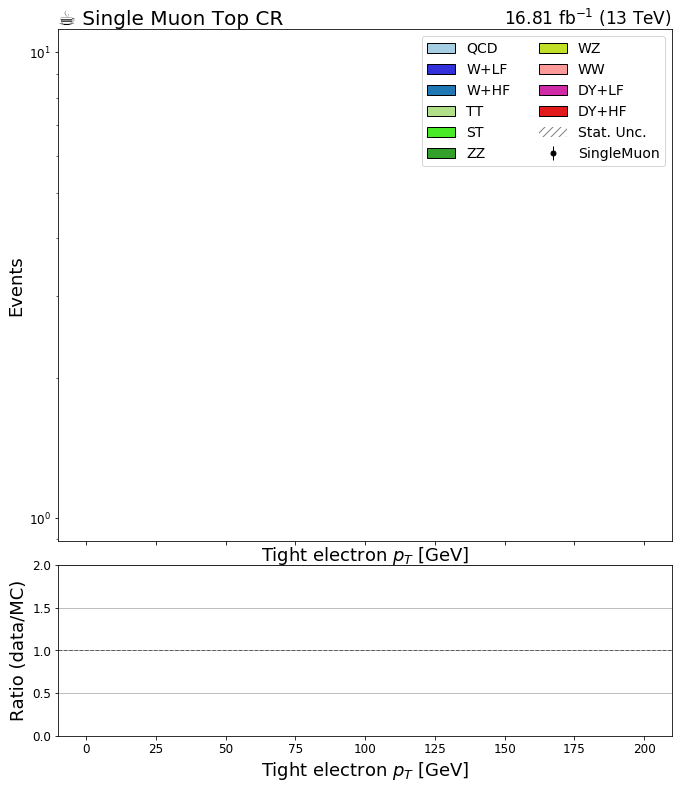

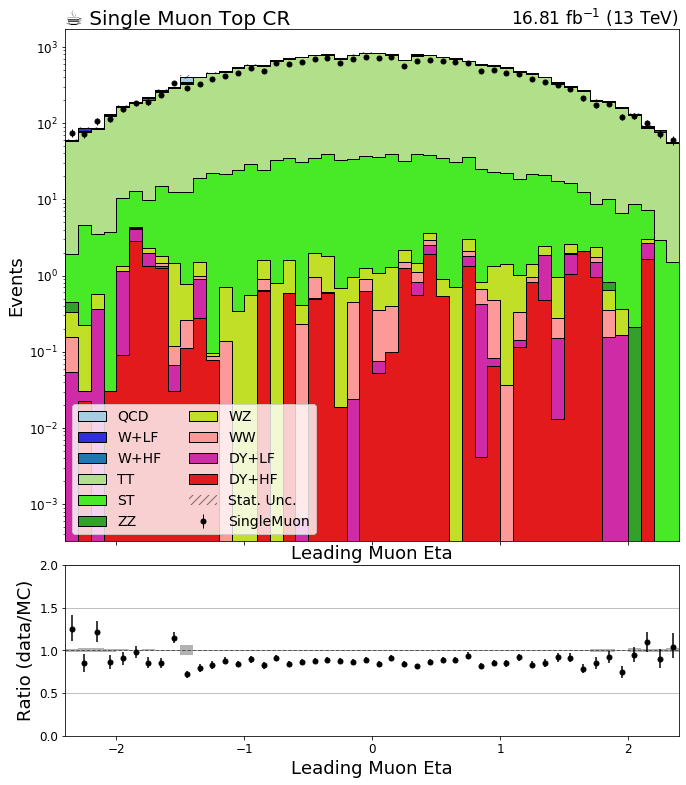

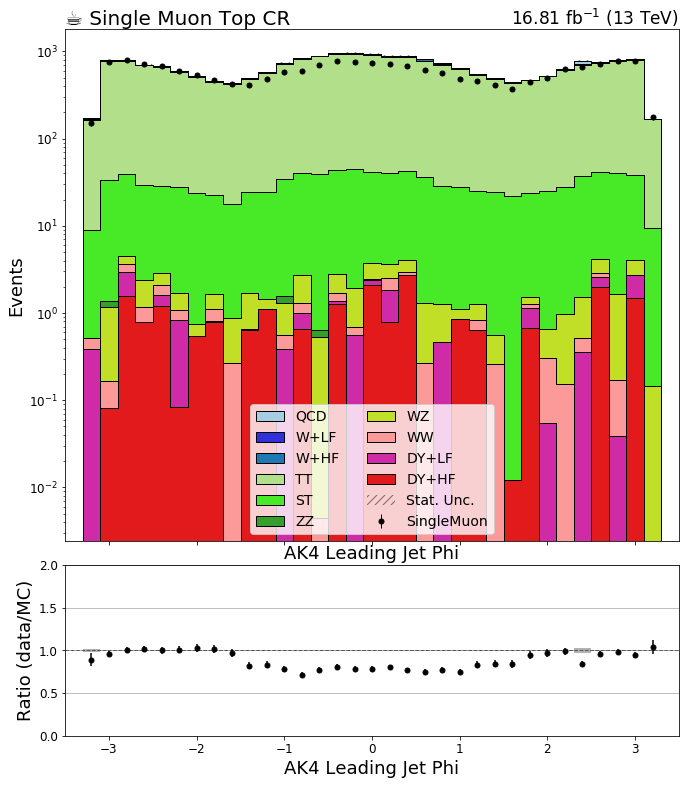

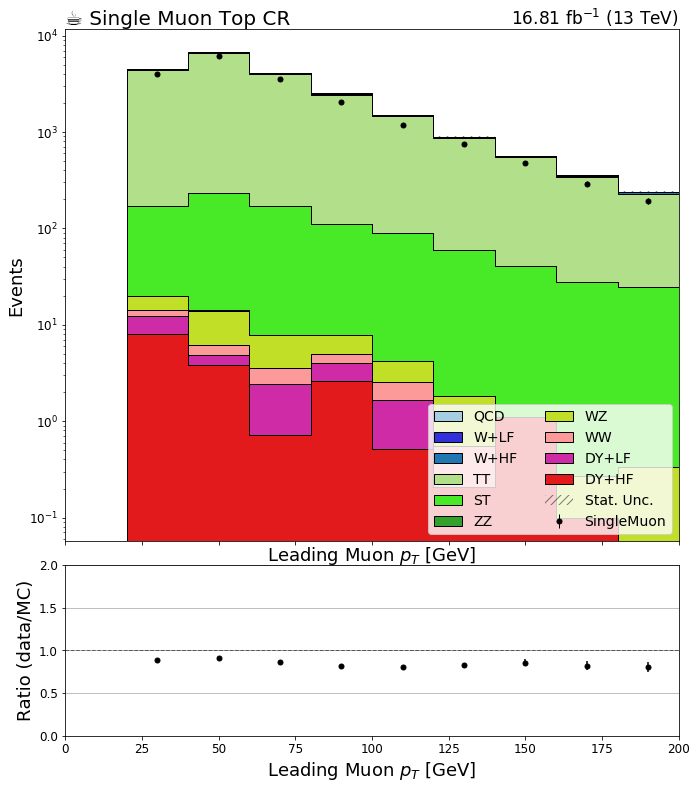

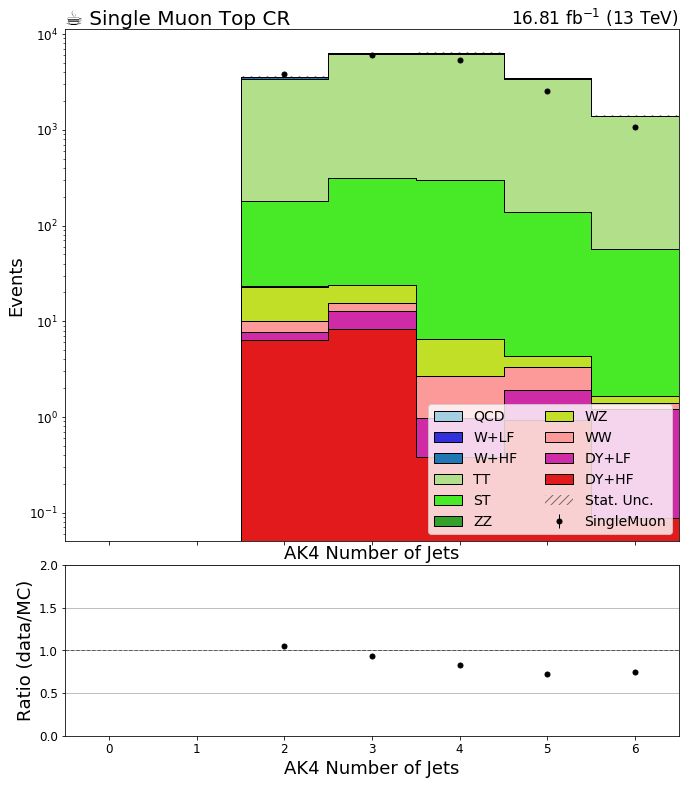

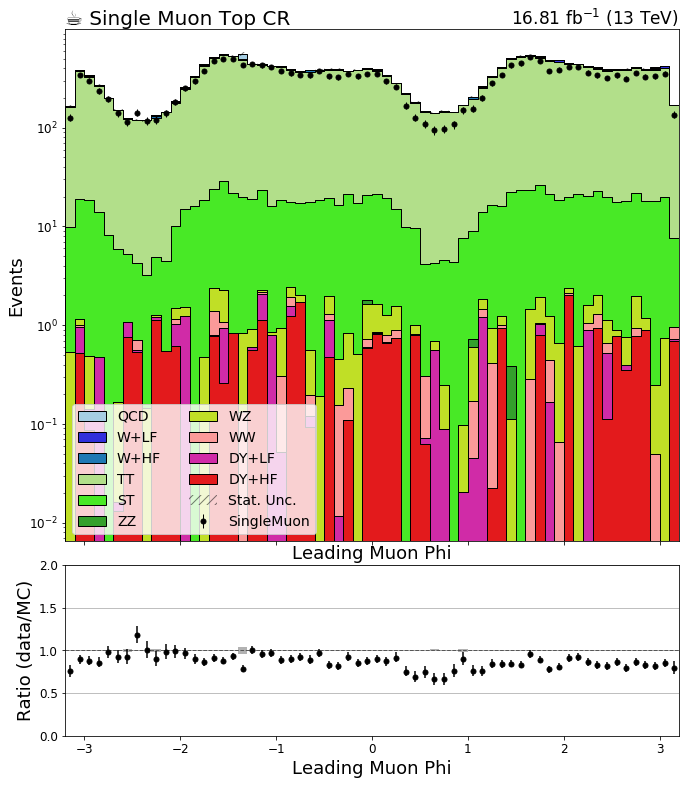

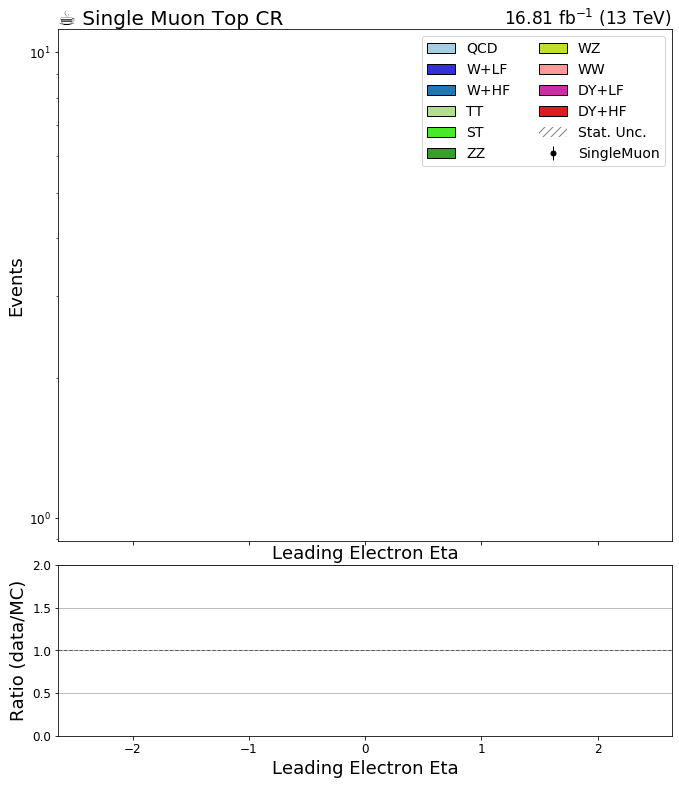

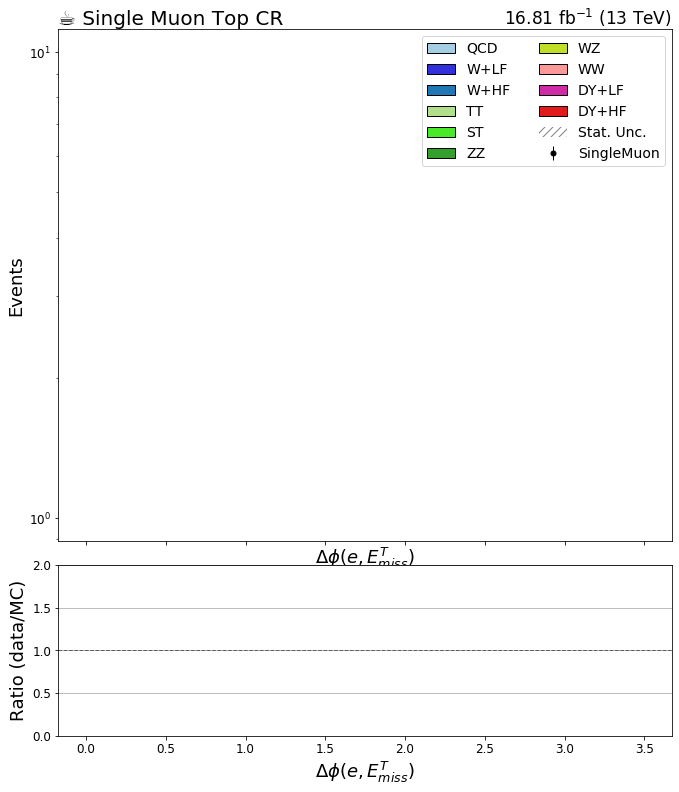

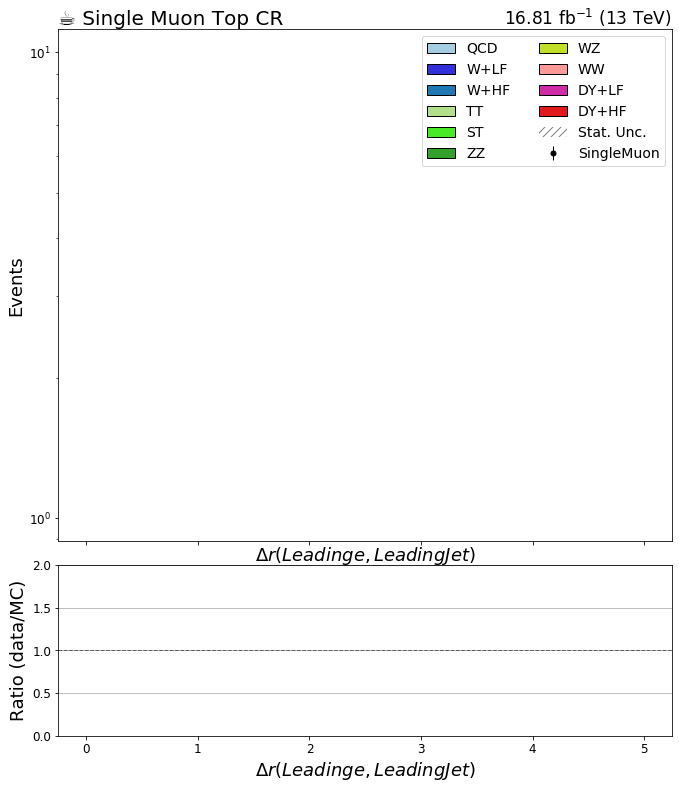

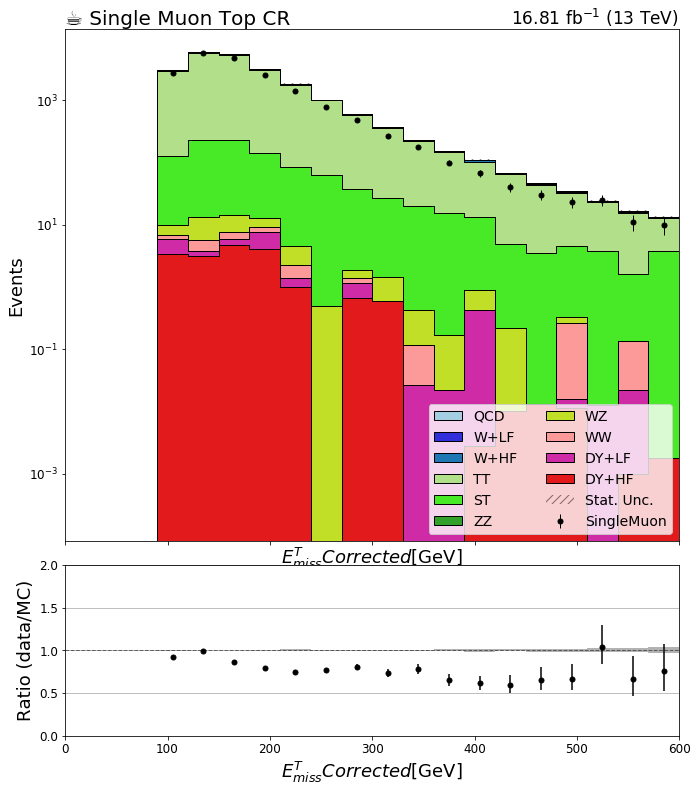

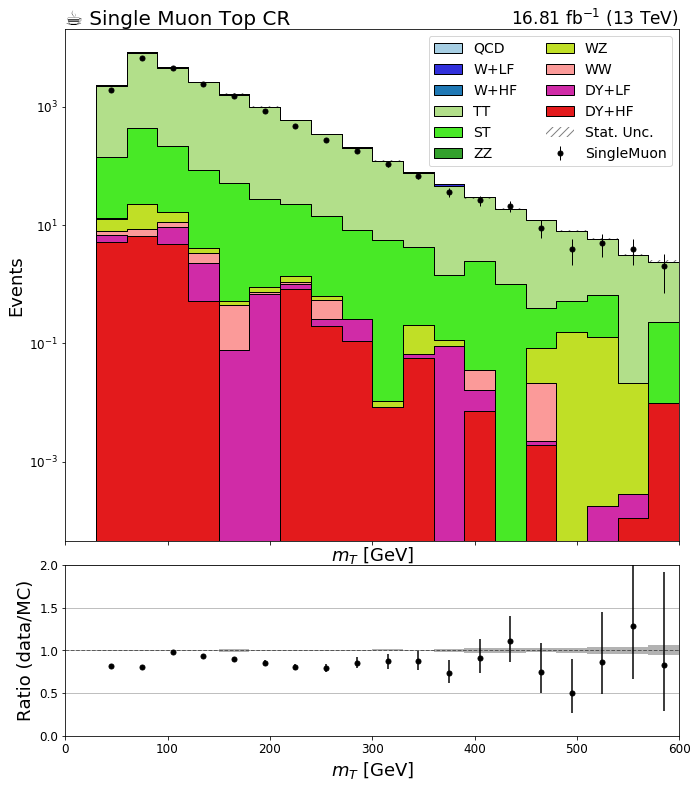

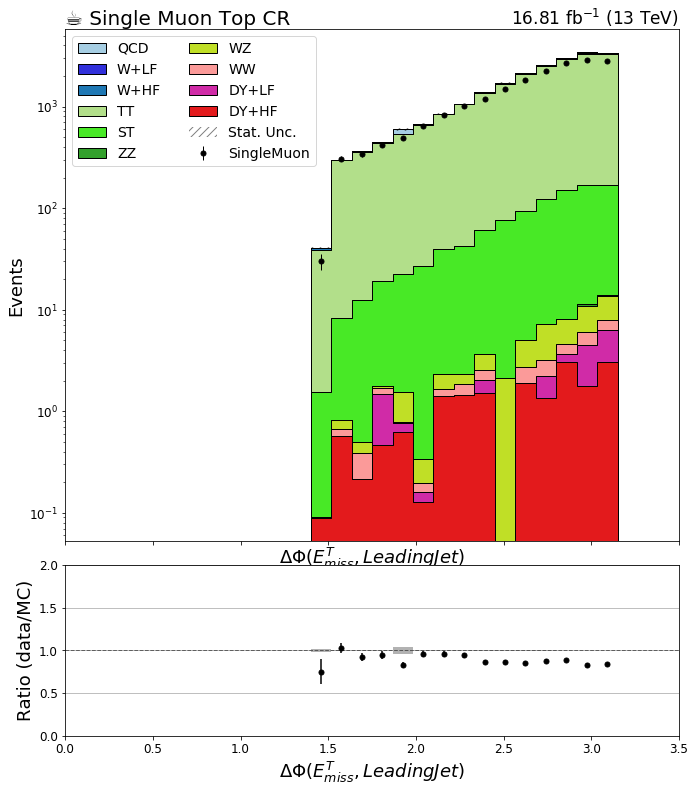

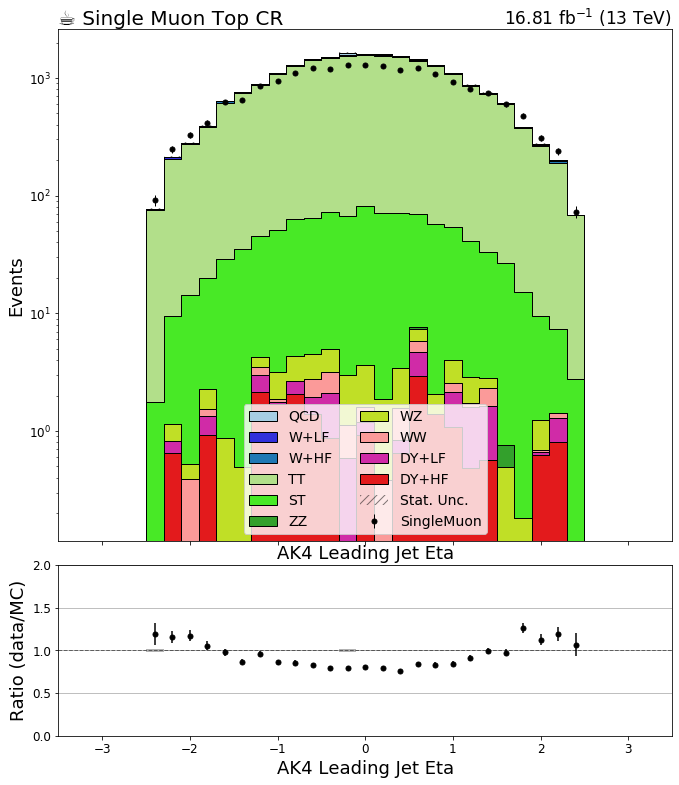

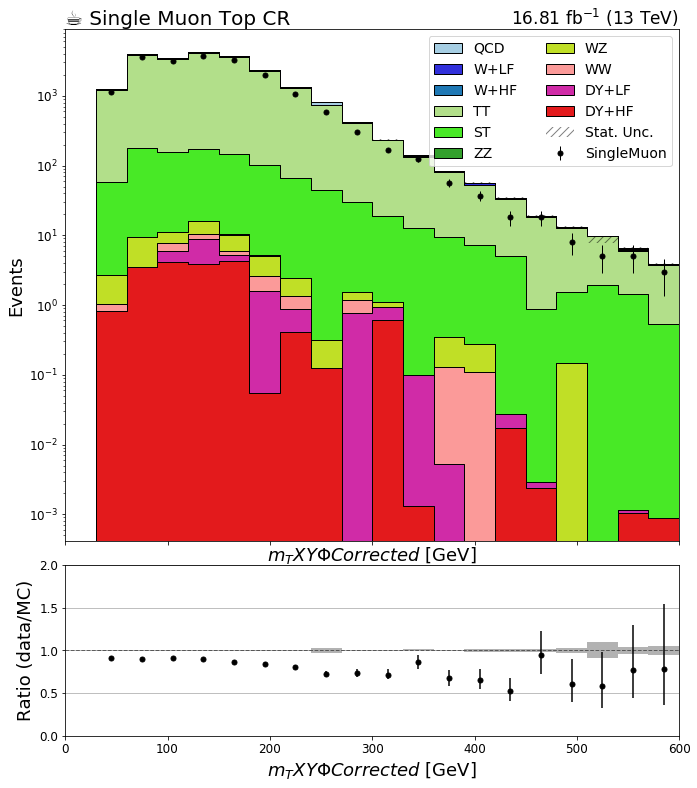

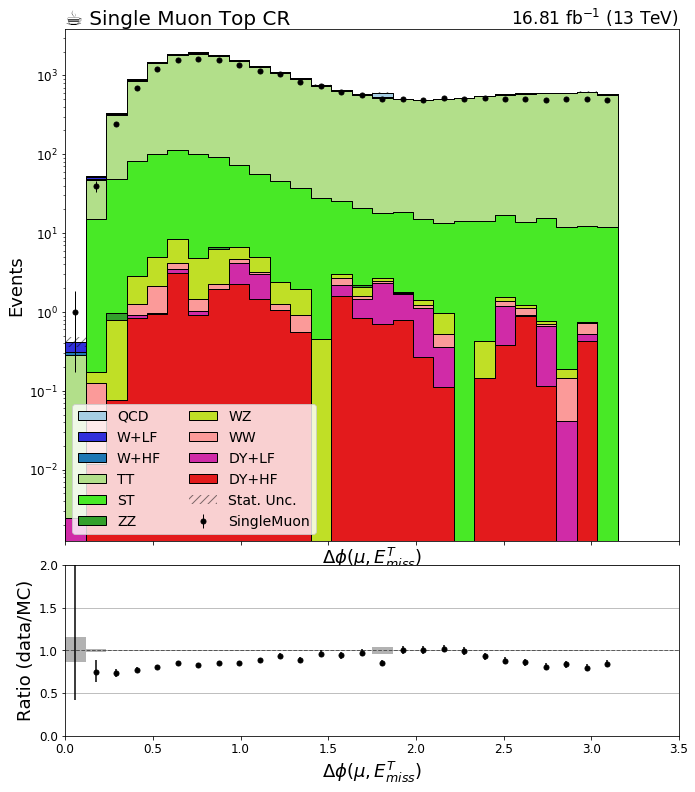

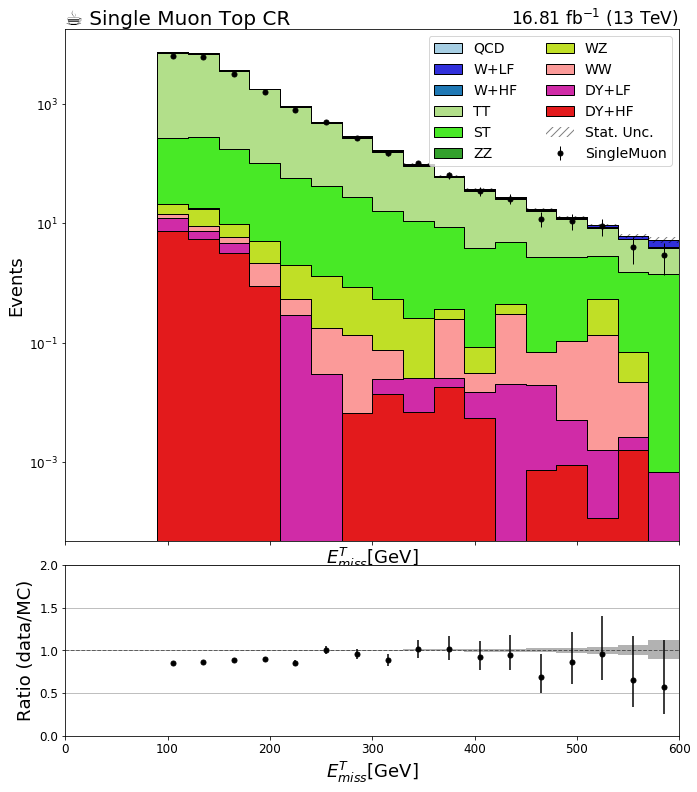

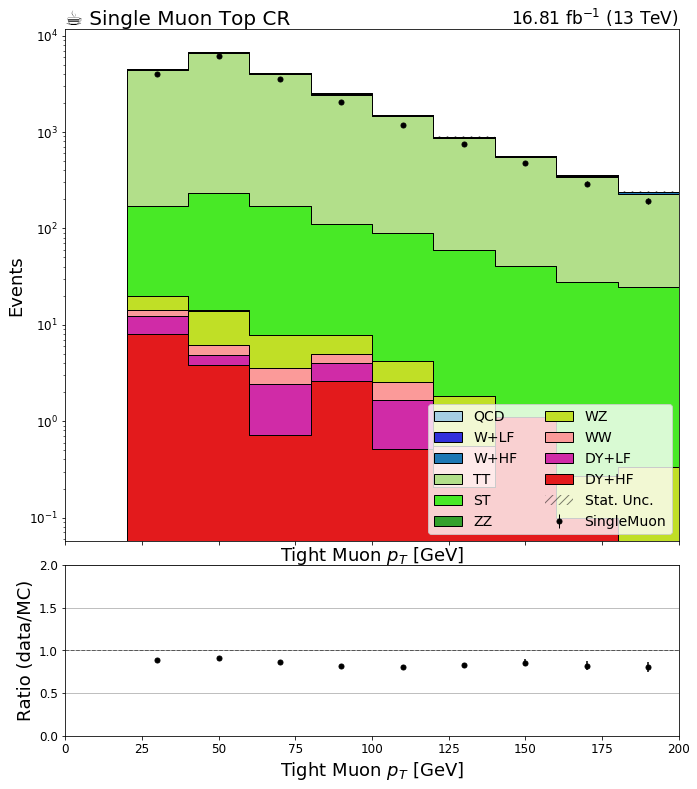

In [6]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2016'
region = 'ttbarm'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('region',j).sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"16.81 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic_preVFP'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic_preVFP'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))